# Sorting Algorithms: Performance, Complexity and Trade-offs

Benchmarking and analysis of Bubble, Merge, Quick and Heap Sort, plus two individual investigations (in-place sorting and sorting stability).

**Team:** Toh Ke Ting, Thawdar Lin Wai  
**Module:** Data Structures and Algorithms (AI), Singapore Polytechnic

In [17]:
# Data Generator Function
# DO NOT CHANGE THIS FUNCTION
import random
random.seed(42)

def datagen(n):
    """Generates a list of n random integers between 0 and 1,000,000."""
    return [random.randint(0, 1_000_000) for _ in range(n)]

# Predefined test cases
test_cases = [
    ('Random Small', datagen(1250)),
    ('Random Medium', datagen(12500)),
    ('Random Big', datagen(125000)), # Not recommended for bubble sort
    ('Already Sorted', list(range(1000))),
    ('Reverse Sorted', list(range(1000, 0, -1))),
    ('All Identical', [42] * 1000),
    ('Few Unique', [random.choice([1, 2, 3, 4, 5]) for _ in range(1000)]),
    ('Almost Sorted', [999] + list(range(2, 999)) + [0]),
]

In [18]:
# Implementation from the slides

def bubbleSort(l):
    while True:
        swapped = False
        for i in range(len(l)-1):
            if l[i]>l[i+1]:
                l[i],l[i+1] = l[i+1],l[i]
                swapped = True
        if not swapped:
            break

def mergeSort(l):
    # Step 1: Split and sort each half
    if len(l) > 1:
        mid = int(len(l)/2)
        leftHalf = l[:mid]
        rightHalf = l[mid:]
 
        mergeSort(leftHalf)
        mergeSort(rightHalf)

        leftIndex,rightIndex,mergeIndex = 0,0,0
        
        # Step 2: Merge two sorted lists into one
        mergeList = l
        while (leftIndex < len(leftHalf) and
                rightIndex < len(rightHalf)):
            if leftHalf[leftIndex] <= rightHalf[rightIndex]:
                mergeList[mergeIndex] = leftHalf[leftIndex]
                leftIndex+=1
            else:
                mergeList[mergeIndex] = rightHalf[rightIndex]
                rightIndex+=1
            mergeIndex+=1

 
        # Handle those items still left in the left half    
        while leftIndex < len(leftHalf):
            mergeList[mergeIndex] = leftHalf[leftIndex]
            leftIndex+=1
            mergeIndex+=1
            
        # Handle those items still left in the right half    
        while rightIndex < len(rightHalf):
            mergeList[mergeIndex] = rightHalf[rightIndex]
            rightIndex+=1
            mergeIndex+=1

### **Part A: Analysis and Comparison of Bubble Sort and Merge Sort**

**Objective**

The objective of Part A is to compare the practical performance of **Bubble Sort** and **Merge Sort** by measuring the exact number of data-value comparisons performed during sorting.

| Algorithm | Theoretical Time Complexity |
| --- | --- |
| Bubble Sort | O(n²) |
| Merge Sort | O(n log n) |

**Experimental Method**

Both sorting algorithms are tested using the same datasets to ensure a fair comparison.

The experiment includes:

1. **Generated datasets**
   Datasets produced using `datagen(n)` for all required dataset sizes.

2. **Predefined test cases**
   Test cases provided in the assignment notebook, including different input arrangements.

3. **Comparison counting**
   Each implementation is modified to count the exact number of comparisons between data values.

4. **Correctness checking**
   The output of each algorithm is compared with Python's built-in `sorted()` function to confirm that the data is sorted correctly.

5. **Visualisation and analysis**
   The comparison counts are presented using tables and graphs to examine how each algorithm behaves as the dataset size increases.

**Areas of Analysis**

The results are analysed based on:

- the growth in comparison count as **n** increases;
- the relationship between the experimental results and theoretical time complexity;
- the effect of the initial input arrangement;
- the scalability of both algorithms for large datasets;
- the time and auxiliary-space trade-offs of each algorithm.

This analysis demonstrates how the theoretical complexities of Bubble Sort and Merge Sort appear in actual experimental results.

In [1]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.ticker import FuncFormatter

### **A1. Comparison-Counting Implementations**

A comparison is counted only when **two dataset values are compared to determine their sorting order**.

| Algorithm       | Comparison Counted                             |
| --------------- | ---------------------------------------------- |
| **Bubble Sort** | `l[i] > l[i + 1]`                              |
| **Merge Sort**  | `leftHalf[leftIndex] <= rightHalf[rightIndex]` |

Loop checks, index checks, assignments, swaps and list slicing are not counted because they do not compare two dataset values.

**Bubble Sort:** The implementation compares all adjacent pairs during each pass and does not reduce the comparison range. It stops early when a complete pass produces no swaps. Therefore, its exact comparison count may differ from other Bubble Sort variants.

**Merge Sort:** Comparisons are counted only when values from the left and right halves are compared during merging. Once one half is empty, the remaining values are copied without additional data-value comparisons.


In [23]:
def bubbleSortCount(l):
    comparisons = 0

    while True:
        swapped = False

        for i in range(len(l) - 1):
            comparisons += 1

            if l[i] > l[i + 1]:
                l[i], l[i + 1] = l[i + 1], l[i]
                swapped = True

        if not swapped:
            break

    return comparisons

In [20]:
def mergeSortCount(l):
    comparisons = 0

    # Step 1: Split and sort each half
    if len(l) > 1:
        mid = len(l) // 2
        leftHalf = l[:mid]
        rightHalf = l[mid:]

        # Accumulate comparisons from recursive calls
        comparisons += mergeSortCount(leftHalf)
        comparisons += mergeSortCount(rightHalf)

        leftIndex = 0
        rightIndex = 0
        mergeIndex = 0

        # Step 2: Merge the two sorted halves
        while (
            leftIndex < len(leftHalf)
            and rightIndex < len(rightHalf)
        ):
            # One comparison between two data values
            comparisons += 1

            if leftHalf[leftIndex] <= rightHalf[rightIndex]:
                l[mergeIndex] = leftHalf[leftIndex]
                leftIndex += 1
            else:
                l[mergeIndex] = rightHalf[rightIndex]
                rightIndex += 1

            mergeIndex += 1

        # Copy remaining left-side elements
        while leftIndex < len(leftHalf):
            l[mergeIndex] = leftHalf[leftIndex]
            leftIndex += 1
            mergeIndex += 1

        # Copy remaining right-side elements
        while rightIndex < len(rightHalf):
            l[mergeIndex] = rightHalf[rightIndex]
            rightIndex += 1
            mergeIndex += 1

    return comparisons

### **A2. Correctness Validation**

**Testing Method**

Before benchmarking, both algorithms were tested using different input conditions.

Each algorithm received a **separate copy of the same list** to ensure a fair comparison.

**Correctness Check**

The sorted output was compared with Python’s built-in: sorted()

A test passed only when:  algorithm_output == sorted(original_data)

In [47]:
validation_cases = [
    ("Random", [5, 3, 1, 4, 2]),
    ("Already Sorted", [1, 2, 3, 4, 5]),
    ("Reverse Sorted", [5, 4, 3, 2, 1]),
    ("All Identical", [7, 7, 7, 7, 7]),
    ("Few Unique", [3, 1, 2, 1, 3]),
    ("Empty List", []),
    ("Single Item", [10])
]

validation_results = []

for case_name, original_data in validation_cases:
    expected = sorted(original_data)

    bubble_data = original_data.copy()
    merge_data = original_data.copy()

    bubble_comparisons = bubbleSortCount(bubble_data)
    merge_comparisons = mergeSortCount(merge_data)

    assert bubble_data == expected
    assert merge_data == expected

    validation_results.append({
        "Test Case": case_name,
        "Bubble Correct": bubble_data == expected,
        "Merge Correct": merge_data == expected,
        "Bubble Comparisons": bubble_comparisons,
        "Merge Comparisons": merge_comparisons
    })

validation_df = pd.DataFrame(validation_results)
validation_df

,Test Case,Bubble Correct,Merge Correct,Bubble Comparisons,Merge Comparisons
0,Random,True,True,16,7
1,Already Sorted,True,True,4,5
2,Reverse Sorted,True,True,20,7
3,All Identical,True,True,4,5
4,Few Unique,True,True,12,8
5,Empty List,True,True,0,0
6,Single Item,True,True,0,0


### **A3. Benchmark Across Required Dataset Sizes**

**Required Dataset Sizes**

Both algorithms are benchmarked using all dataset sizes specified in the assignment:

`5, 10, 20, 100, 200, 400, 800, 1600, 5000, 10000, 100000`

**Fair Comparison**

For each value of (n):

1. `datagen(n)` is called once to generate the dataset.
2. Separate copies of the same dataset are passed to Bubble Sort and Merge Sort.
3. Both sorted outputs are checked against Python’s `sorted()` function.
4. The comparison counts are recorded only after correctness is confirmed.

This ensures that both algorithms process **identical input data** under the same conditions.

> **Note:** Bubble Sort on 100,000 random values takes a substantial amount of time. The saved benchmark output should therefore be retained to avoid unnecessary repeated runs.


A fixed random seed is reset before the benchmark so that the generated datasets are reproducible across repeated executions.

In [48]:
# Fixed seed for reproducible Part A benchmarking
PART_A_SEED = 1507
random.seed(PART_A_SEED)

required_sizes = [
    5, 10, 20, 100, 200, 400,
    800, 1600, 5000, 10000, 100000
]

benchmark_results = []

for n in required_sizes:
    print(f"Running benchmark for n = {n}...")

    original_data = datagen(n)
    expected = sorted(original_data)

    bubble_data = original_data.copy()
    merge_data = original_data.copy()

    bubble_comparisons = bubbleSortCount(bubble_data)
    merge_comparisons = mergeSortCount(merge_data)

    assert bubble_data == expected
    assert merge_data == expected

    benchmark_results.append({
        "Dataset Size (n)": n,
        "Bubble Sort Comparisons": bubble_comparisons,
        "Merge Sort Comparisons": merge_comparisons
    })

comparison_df = pd.DataFrame(benchmark_results)

assert comparison_df["Dataset Size (n)"].tolist() == required_sizes
assert len(comparison_df) == 11

comparison_df

Running benchmark for n = 5...
Running benchmark for n = 10...
Running benchmark for n = 20...
Running benchmark for n = 100...
Running benchmark for n = 200...
Running benchmark for n = 400...
Running benchmark for n = 800...
Running benchmark for n = 1600...
Running benchmark for n = 5000...
Running benchmark for n = 10000...
Running benchmark for n = 100000...


,Dataset Size (n),Bubble Sort Comparisons,Merge Sort Comparisons
0,5,8,7
1,10,45,20
2,20,323,64
3,100,8514,534
4,200,37412,1283
5,400,146433,2965
6,800,613632,6706
7,1600,2504034,15073
8,5000,24405118,55198
9,10000,98820117,120404


### **Normalized Comparison Counts**


To verify that the empirical comparison counts match their theoretical time complexities, each algorithm's comparison count is divided by its expected complexity term:

- Bubble Sort comparisons are divided by **n²**.
- Merge Sort comparisons are divided by **n log₂ n**.

If the resulting ratio stays roughly constant as **n** increases, this confirms that the empirical growth rate matches the theoretical complexity class.

In [49]:
normalized_df = comparison_df.copy()

normalized_df["Bubble / n²"] = (
    normalized_df["Bubble Sort Comparisons"]
    / (normalized_df["Dataset Size (n)"] ** 2)
)

normalized_df["Merge / (n log₂ n)"] = (
    normalized_df["Merge Sort Comparisons"]
    / (
        normalized_df["Dataset Size (n)"]
        * np.log2(normalized_df["Dataset Size (n)"])
    )
)

normalized_df[
    [
        "Dataset Size (n)",
        "Bubble / n²",
        "Merge / (n log₂ n)"
    ]
].round(4)

,Dataset Size (n),Bubble / n²,Merge / (n log₂ n)
0,5,0.3200,0.6029
1,10,0.4500,0.6021
2,20,0.8075,0.7404
3,100,0.8514,0.8038
4,200,0.9353,0.8392
5,400,0.9152,0.8575
6,800,0.9588,0.8692
7,1600,0.9781,0.8851
8,5000,0.9762,0.8984
9,10000,0.9882,0.9061


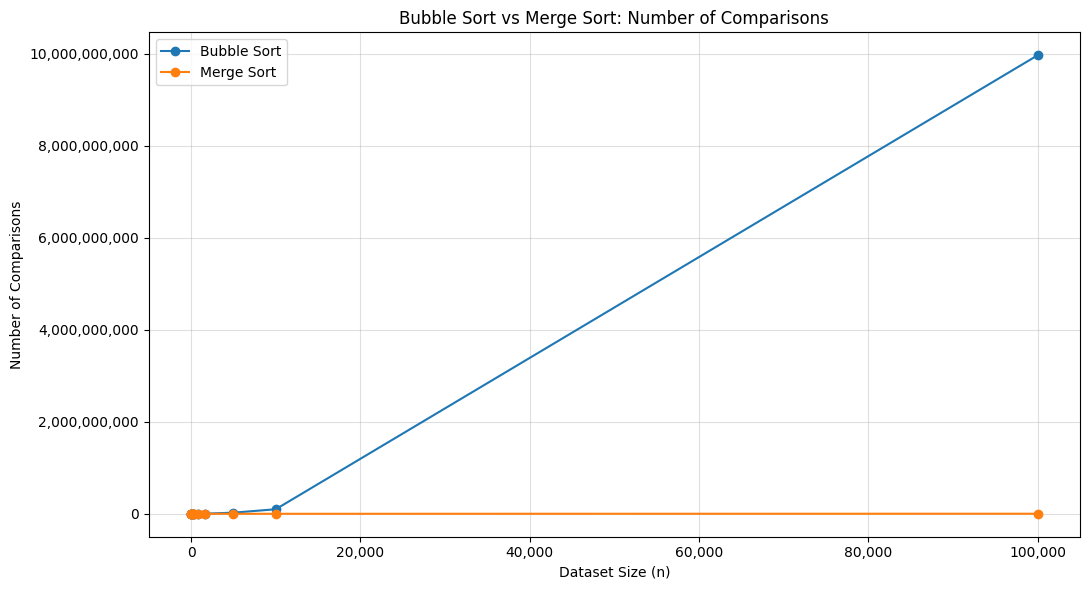

In [50]:
plt.figure(figsize=(11, 6))
plt.plot(comparison_df["Dataset Size (n)"], comparison_df["Bubble Sort Comparisons"], marker="o", label="Bubble Sort")
plt.plot(comparison_df["Dataset Size (n)"], comparison_df["Merge Sort Comparisons"], marker="o", label="Merge Sort")

plt.xlabel("Dataset Size (n)")
plt.ylabel("Number of Comparisons")
plt.title("Bubble Sort vs Merge Sort: Number of Comparisons")

plt.legend()
plt.grid(True, alpha=0.4)

ax = plt.gca()
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, position: f"{value:,.0f}"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, position: f"{value:,.0f}"))

plt.tight_layout()
plt.show()

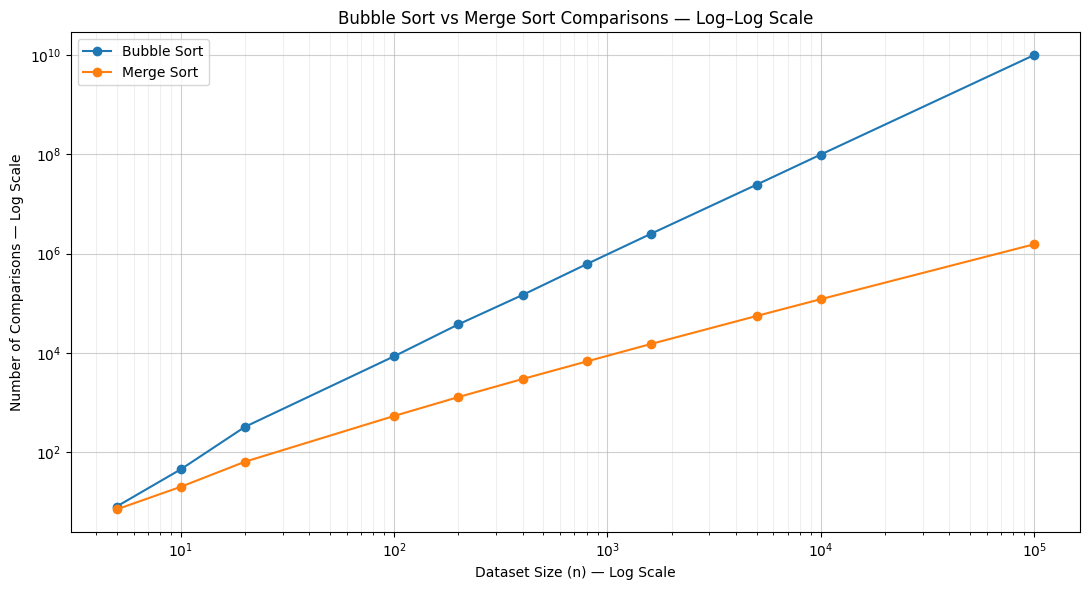

In [51]:
plt.figure(figsize=(11, 6))
plt.plot(comparison_df["Dataset Size (n)"], comparison_df["Bubble Sort Comparisons"], marker="o", label="Bubble Sort")
plt.plot(comparison_df["Dataset Size (n)"], comparison_df["Merge Sort Comparisons"], marker="o", label="Merge Sort")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Dataset Size (n) — Log Scale")
plt.ylabel("Number of Comparisons — Log Scale")
plt.title("Bubble Sort vs Merge Sort Comparisons — Log–Log Scale")

plt.legend()
plt.grid(True, which="major", alpha=0.6)
plt.grid(True, which="minor", alpha=0.2)
plt.tight_layout()
plt.show()

### **A3.1 Analysis of Growth Rate**

#### **Linear-Scale Graph**

The linear-scale graph shows that the **number of comparisons made by Bubble Sort grows much faster** than that of Merge Sort.

At n = 100,000:

| Algorithm | Number of Comparisons |
|---|---:|
| **Bubble Sort** | `9,970,700,292` |
| **Merge Sort** | `1,536,341` |

Bubble Sort made approximately **6,490 times more comparisons** than Merge Sort. Due to this large difference, the Merge Sort curve appears close to the horizontal axis.

#### **Log-Log Graph**

The log-log graph displays the growth trends of both algorithms more clearly without changing the underlying results.

When the dataset size increased from 5,000 to 10,000:

- **Bubble Sort** comparisons increased from `24,405,118` to `98,820,117`, approximately **4.05 times**. This is consistent with O(n²) growth.
- **Merge Sort** comparisons increased from `55,198` to `120,404`, approximately **2.18 times**. This slower growth is consistent with O(n log n).

#### **Normalized Comparison Counts**

To examine whether the empirical comparison counts are consistent with their theoretical growth rates, each algorithm's comparison count is divided by its expected complexity term:

- Bubble Sort comparisons are divided by n².
- Merge Sort comparisons are divided by n log₂ n.

If the resulting ratio remains relatively stable as n increases, this provides empirical evidence that the observed growth is consistent with the expected complexity class.

The small values of n show more fluctuation because constant-factor effects have a greater influence on small datasets. From n = 100 onward, the Bubble Sort normalized value generally approaches `1.0`, while the Merge Sort value remains within approximately `0.80–0.93`.

These results support empirical growth consistent with O(n²) for Bubble Sort and O(n log n) for Merge Sort.

#### **Conclusion**

- **Bubble Sort** becomes increasingly inefficient as the dataset size grows.
- **Merge Sort** scales much more effectively for large datasets.

The performance difference becomes increasingly significant because Big-O notation describes the **rate of growth**, rather than the exact number of operations.

### **A4. Benchmark on Predefined Test Cases**

**Purpose of the Benchmark**

The predefined test cases are used to investigate:

1. how increasing dataset size affects each algorithm on **random inputs**;
2. how the **initial input arrangement** affects each algorithm when the datasets have approximately the same size.

**Testing Method**

For each test case:

- Bubble Sort and Merge Sort receive separate copies of the same dataset.
- Both sorted outputs are verified against Python's `sorted()` result.
- The number of comparisons is recorded as the primary performance measure.

### **A4.1 Overall Predefined Test-Case Results**

The table below presents the **comparison count** and **runtime** of both algorithms across all eight predefined test cases.

**Performance Measures**

- **Comparison count** is the primary performance measure.
- **Runtime** is included only as supplementary evidence because each value was recorded from a single execution and may be affected by hardware, processor scheduling, and background applications.

**Comparison Ratio**

The comparison ratio is calculated as:

$$
\text{Comparison Ratio} = \frac{\text{Bubble Sort Comparisons}}{\text{Merge Sort Comparisons}}
$$

- A ratio **greater than 1** means Bubble Sort made more comparisons.
- A ratio **below 1** means Bubble Sort made fewer comparisons.
- A ratio **equal to 1** means both algorithms made the same number of comparisons.

> **Note:** The `Random Big` dataset requires a long Bubble Sort execution, but it is included to complete the benchmark across all predefined test cases.

In [52]:
predefined_results = []

for case_name, original_data in test_cases:
    print(f"Running {case_name}...")

    expected = sorted(original_data)

    bubble_data = original_data.copy()
    merge_data = original_data.copy()

    bubble_start = time.perf_counter()
    bubble_comparisons = bubbleSortCount(bubble_data)
    bubble_time = time.perf_counter() - bubble_start

    merge_start = time.perf_counter()
    merge_comparisons = mergeSortCount(merge_data)
    merge_time = time.perf_counter() - merge_start

    assert bubble_data == expected
    assert merge_data == expected

    predefined_results.append({
        "Test Case": case_name,
        "Dataset Size (n)": len(original_data),
        "Bubble Sort Comparisons": bubble_comparisons,
        "Merge Sort Comparisons": merge_comparisons,
        "Bubble Sort Time (s)": round(bubble_time, 4),
        "Merge Sort Time (s)": round(merge_time, 4)
    })

predefined_df = pd.DataFrame(predefined_results)

predefined_df["Comparison Ratio (Bubble ÷ Merge)"] = (
    predefined_df["Bubble Sort Comparisons"]
    / predefined_df["Merge Sort Comparisons"]
).round(2)

predefined_df

Running Random Small...
Running Random Medium...
Running Random Big...
Running Already Sorted...
Running Reverse Sorted...
Running All Identical...
Running Few Unique...
Running Almost Sorted...


,Test Case,Dataset Size (n),Bubble Sort Comparisons,Merge Sort Comparisons,Bubble Sort Time (s),Merge Sort Time (s),Comparison Ratio (Bubble ÷ Merge)
0,Random Small,1250,1531274,11292,0.3263,0.0024,135.61
1,Random Medium,12500,155550055,154564,32.9306,0.0833,1006.38
2,Random Big,125000,15596500227,1959451,4188.1178,0.9296,7959.63
3,Already Sorted,1000,999,4932,0.0002,0.0046,0.20
4,Reverse Sorted,1000,999000,5044,0.2349,0.0041,198.06
5,All Identical,1000,999,4932,0.0002,0.0036,0.20
6,Few Unique,1000,774225,8086,0.1737,0.0044,95.75
7,Almost Sorted,999,997002,5921,0.1633,0.0030,168.38


### **A4.2 Effect of Dataset Size on Random Inputs**

The three predefined random datasets are used to examine how increasing dataset size affects both algorithms:

| Dataset | Size |
| --- | ---: |
| **Random Small** | n = 1,250 |
| **Random Medium** | n = 12,500 |
| **Random Big** | n = 125,000 |

Each dataset is **ten times larger** than the previous one.

A **log-log line graph** is used because both the dataset sizes and comparison counts cover large ranges. The logarithmic scales allow the growth patterns of Bubble Sort and Merge Sort to be compared clearly on the same graph.

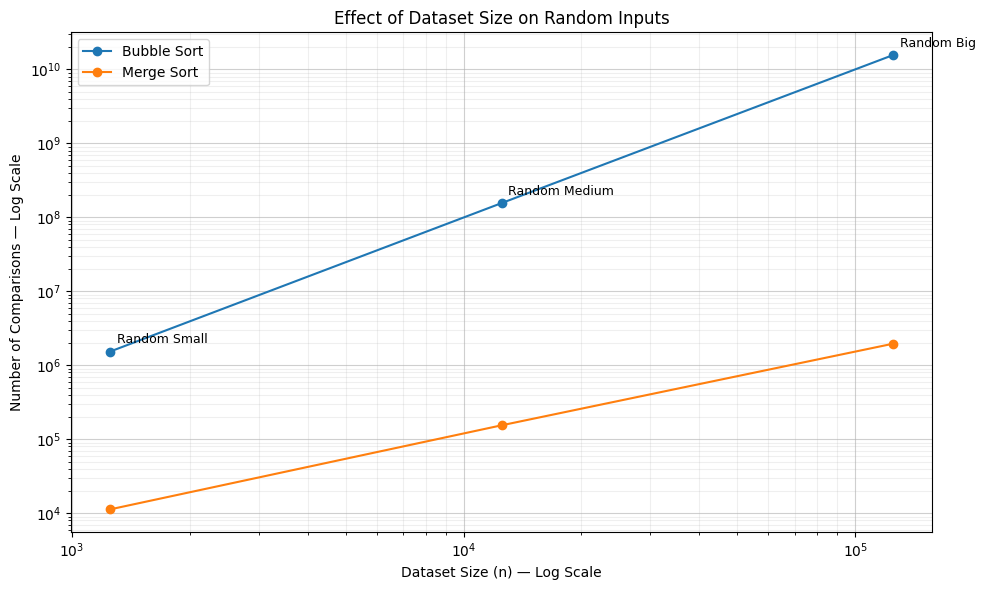

In [53]:
random_case_order = ["Random Small", "Random Medium", "Random Big"]

random_df = predefined_df[predefined_df["Test Case"].isin(random_case_order)].copy()
random_df["Test Case"] = pd.Categorical(random_df["Test Case"], categories=random_case_order, ordered=True)
random_df = random_df.sort_values("Test Case").reset_index(drop=True)

plt.figure(figsize=(10, 6))
plt.plot(random_df["Dataset Size (n)"], random_df["Bubble Sort Comparisons"], marker="o", label="Bubble Sort")
plt.plot(random_df["Dataset Size (n)"], random_df["Merge Sort Comparisons"], marker="o", label="Merge Sort")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("Dataset Size (n) — Log Scale")
plt.ylabel("Number of Comparisons — Log Scale")
plt.title("Effect of Dataset Size on Random Inputs")

for _, row in random_df.iterrows():
    plt.annotate(row["Test Case"], (row["Dataset Size (n)"], row["Bubble Sort Comparisons"]),
                 xytext=(5, 6), textcoords="offset points", fontsize=9)

plt.legend()
plt.grid(True, which="major", alpha=0.6)
plt.grid(True, which="minor", alpha=0.2)
plt.tight_layout()
plt.show()

In [54]:
random_cases = predefined_df[
    predefined_df["Test Case"].isin(["Random Small", "Random Medium", "Random Big"])
].copy().set_index("Test Case")

small_n = random_cases.loc["Random Small", "Dataset Size (n)"]
big_n = random_cases.loc["Random Big", "Dataset Size (n)"]

bubble_small = random_cases.loc["Random Small", "Bubble Sort Comparisons"]
bubble_big = random_cases.loc["Random Big", "Bubble Sort Comparisons"]

merge_small = random_cases.loc["Random Small", "Merge Sort Comparisons"]
merge_big = random_cases.loc["Random Big", "Merge Sort Comparisons"]

size_growth = big_n / small_n
bubble_growth = bubble_big / bubble_small
merge_growth = merge_big / merge_small

print("Dataset size growth:", round(size_growth, 2), "times")
print("Bubble Sort comparison growth:", round(bubble_growth, 2), "times")
print("Merge Sort comparison growth:", round(merge_growth, 2), "times")

Dataset size growth: 100.0 times
Bubble Sort comparison growth: 10185.31 times
Merge Sort comparison growth: 173.53 times


#### **Analysis of Random Dataset Growth**

The three predefined random datasets increase by a factor of ten at each stage:

| Dataset | Size |
| --- | ---: |
| **Random Small** | n = 1,250 |
| **Random Medium** | n = 12,500 |
| **Random Big** | n = 125,000 |

#### **Growth in Comparison Count**

From **Random Small** to **Random Big**, the dataset size increased by **100 times**.

- **Bubble Sort** comparisons increased from `1,531,274` to `15,596,500,227` — approximately **10,185 times**.
- **Merge Sort** comparisons increased from `11,292` to `1,959,451` — approximately **174 times**.

The Bubble-to-Merge comparison ratio also increased from **135.61** to **7,959.63**. This shows that Bubble Sort's relative disadvantage became much greater as the dataset size increased.

#### **Relationship to Time Complexity**

These results support the growth trends observed in Section A3:

- Bubble Sort shows approximately **quadratic growth**, consistent with O(n²).
- Merge Sort grows much more slowly, consistent with O(n log n).

#### **Runtime Evidence**

For the **Random Big** dataset, where n=125,000:

| Algorithm | Runtime |
|---|---:|
| **Bubble Sort** | Approximately `4,188.12 s` |
| **Merge Sort** | Approximately `0.93 s` |

Bubble Sort also made approximately **7,959.63 times more comparisons** than Merge Sort.

Since execution time is hardware-dependent, the **comparison count remains the primary performance measure**, while runtime is used only as supporting evidence.

### **A4.3 Effect of Input Arrangement**

To examine how input arrangement affects each algorithm, five structured test cases are compared:

* **Already Sorted**
* **Reverse Sorted**
* **All Identical**
* **Few Unique**
* **Almost Sorted**

Most datasets contain approximately **1,000 elements**, making their comparison counts more directly comparable than the differently sized random datasets.

> **Note:** The `Almost Sorted` dataset contains **999 elements**, as this is the size of the predefined list provided in the notebook.


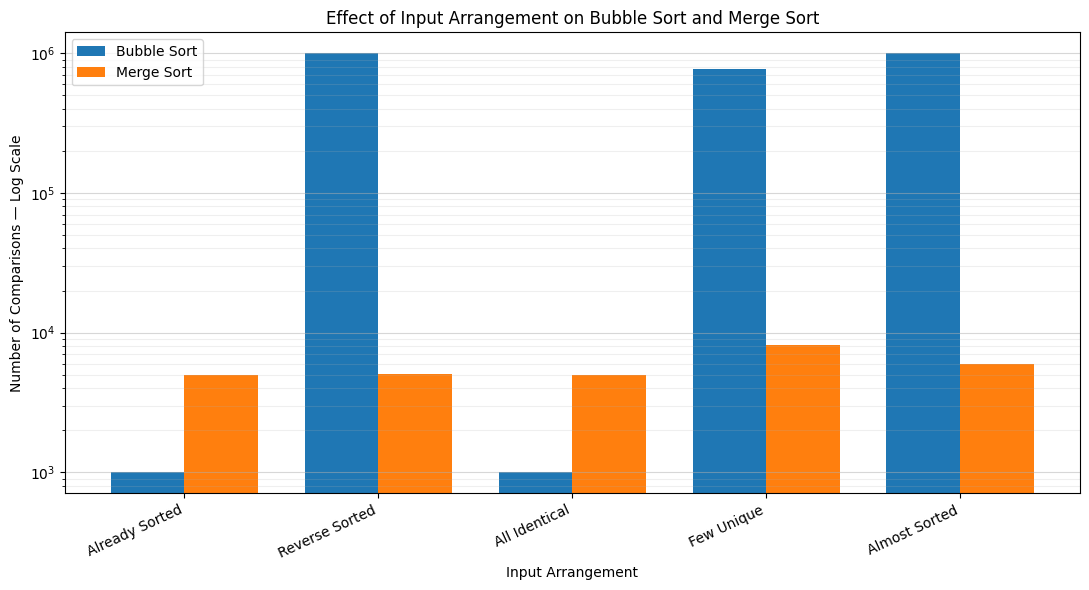

In [55]:
structured_cases = ["Already Sorted", "Reverse Sorted", "All Identical", "Few Unique", "Almost Sorted"]
structured_df = predefined_df[predefined_df["Test Case"].isin(structured_cases)].copy()

x = np.arange(len(structured_df))
bar_width = 0.38

plt.figure(figsize=(11, 6))
plt.bar(x - bar_width / 2, structured_df["Bubble Sort Comparisons"], width=bar_width, label="Bubble Sort")
plt.bar(x + bar_width / 2, structured_df["Merge Sort Comparisons"], width=bar_width, label="Merge Sort")

plt.xticks(x, structured_df["Test Case"], rotation=25, ha="right")
plt.yscale("log")

plt.xlabel("Input Arrangement")
plt.ylabel("Number of Comparisons — Log Scale")
plt.title("Effect of Input Arrangement on Bubble Sort and Merge Sort")

plt.legend()
plt.grid(True, which="major", axis="y", alpha=0.5)
plt.grid(True, which="minor", axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

#### **Bubble Sort**

Bubble Sort is **highly sensitive to the initial arrangement of the data**.

| Input Arrangement | Comparisons | Explanation |
| --- | ---: | --- |
| **Already Sorted** | `999` | No swaps occurred during the first pass, so the algorithm terminated early. |
| **All Identical** | `999` | Equal values were not swapped, allowing early termination after one pass. |
| **Reverse Sorted** | `999,000` | Every pass required swaps, producing the **O(n²)** worst case. |
| **Almost Sorted** | `997,002` | The smallest value was at the end and could move left by only one position per pass. |
| **Few Unique** | `774,225` | Duplicate values reduced some swaps, but the remaining disorder still required many passes. |

The **Already Sorted** and **All Identical** results demonstrate the **O(n)** best-case behaviour of this early-termination implementation.

For the **Reverse Sorted** dataset, this implementation compares all **n − 1** adjacent pairs during every pass. With **n = 1000**, it performs 999 passes containing swaps, followed by one final pass with no swaps:

$$
1000 \times 999 = 999{,}000
$$

This differs from:

$$
\frac{n(n-1)}{2}
$$

The second formula applies to another Bubble Sort variant that reduces the comparison range after each pass.

The **Almost Sorted** result also shows that an almost-sorted dataset is not always favourable. The **position of the misplaced values** affects how many passes Bubble Sort requires.

#### **Merge Sort**

Merge Sort was **less sensitive to the initial input arrangement**. Its comparison counts across the structured datasets ranged only from `4,932` to `8,086`.

- It recursively divides the entire list even when the data is already sorted.
- It cannot terminate early like Bubble Sort.
- Its overall performance remains **O(n log n)**.
- Comparisons stop once either the left or right half becomes empty.
- For **Already Sorted** and **All Identical** inputs, one half was often exhausted quickly.
- For identical values, the `<=` condition consistently selected the value from the left half first.
- The supplied **Few Unique** dataset required more comparisons because values from both halves remained active for longer during merging.

The Few Unique result depends on the specific arrangement of the supplied dataset and does not mean every few-unique dataset will produce the same count.

#### **Overall Comparison**

| Algorithm | Effect of Input Arrangement |
| --- | --- |
| **Bubble Sort** | Comparisons ranged from `999` to `999,000`, showing large variation. |
| **Merge Sort** | Comparisons ranged from `4,932` to `8,086`, showing much smaller variation. |

Therefore, Bubble Sort's performance depends strongly on the initial arrangement, while Merge Sort provides **more consistent performance across different input arrangements**.

### **A5. Theoretical Comparison and Conclusion**

| Algorithm | Best-Case Time | Average-Case Time | Worst-Case Time | Auxiliary Space | Input Sensitivity |
| --- | ---: | ---: | ---: | ---: | --- |
| Bubble Sort used in this experiment | O(n) | O(n²) | O(n²) | O(1) | Highly sensitive to the initial order |
| Merge Sort used in this experiment | O(n log n) | O(n log n) | O(n log n) | O(n) | Relatively consistent across input orders |

Bubble Sort is an in-place algorithm because it rearranges elements within the original list using constant auxiliary space. The early-termination condition gives it a best-case complexity of **O(n)** when no swaps are needed.

The Merge Sort implementation creates `leftHalf` and `rightHalf` lists during recursion. It therefore requires **O(n)** auxiliary space, but provides consistent **O(n log n)** performance.

Overall, the experimental results demonstrate that Bubble Sort's performance depends strongly on both dataset size and input arrangement. Its early-termination condition allows it to process already-sorted and all-identical inputs using only **n − 1** comparisons, while its **O(1)** auxiliary-space requirement may also be useful when memory is highly limited. However, its **O(n²)** average- and worst-case growth makes it unsuitable for large or unfavourably arranged datasets.

Merge Sort requires **O(n)** auxiliary space because it creates temporary sublists during recursion. However, its comparison count grows at **O(n log n)** and varies much less across different input arrangements. Therefore, Merge Sort is substantially more scalable and generally more suitable for large datasets when sufficient memory is available.

## **Part B: Exploration and Analysis of Quick Sort and Heap Sort**

**Objective**

Part B explores and compares two additional comparison-based sorting algorithms:

1. **Quick Sort**, using median-of-three pivot selection and three-way partitioning.
2. **Heap Sort**, using an iterative binary max-heap.

Both algorithms are evaluated using the same **Count, Benchmark, Visualise, and Analyse** process applied in Part A.

**Why These Algorithms Were Selected**

| Algorithm | Main Characteristic |
|---|---|
| **Quick Sort** | Efficient average-case performance, but behaviour depends on pivot selection and partition balance. |
| **Heap Sort** | Guarantees O(n log n) time and uses O(1) auxiliary space. |

These two algorithms provide a meaningful comparison because they differ in both **worst-case time complexity** and **auxiliary-space complexity**:

- Quick Sort has an average time complexity of O(n log n), but can degrade to O(n²) in the worst case.
- Heap Sort maintains O(n log n) time even in the worst case.
- Quick Sort requires additional space for the recursive call stack.
- The iterative Heap Sort implementation requires only O(1) auxiliary space.

## **B1. Quick Sort**

Quick Sort is a **divide-and-conquer** sorting algorithm. It selects a pivot, partitions the data around that pivot, and recursively sorts the resulting partitions.

**Implementation Used**

This implementation uses two techniques:

1. **Median-of-three pivot selection**  
   The pivot is chosen as the median of the **first, middle and last values**. This reduces the chance of immediately selecting an extreme value as the pivot.

2. **Three-way partitioning**  
   Values are divided into three regions:
   - values **less than** the pivot;
   - values **equal to** the pivot;
   - values **greater than** the pivot.

Values equal to the pivot do not need to be sorted again, which can improve performance when the dataset contains many duplicates.

The values are rearranged within the original list. However, recursive calls require additional call-stack space.

### **B1.1 Quick Sort Comparison Counting**

A comparison is counted only when **two dataset values are compared**.

Comparisons occur in two stages:

| Stage | Comparison |
|---|---|
| **Pivot selection** | `a > b` and `b > c` when choosing the median-of-three pivot |
| **Partitioning** | `l[i] < pivot` and, when required, `l[i] > pivot` |

During pivot selection, exactly **3 comparisons** are made.

During partitioning:

- `l[i] < pivot` → **1 comparison**
- `l[i] == pivot` → **2 comparisons**
- `l[i] > pivot` → **2 comparisons**

Index checks, loop conditions, assignments and swaps are not counted because they do not compare two dataset values.

In [56]:
def quickSortCount(l):
    comparisons = 0

    def medianOfThree(a, b, c):
        nonlocal comparisons

        # Comparison 1
        comparisons += 1
        if a > b:
            a, b = b, a

        # Comparison 2
        comparisons += 1
        if b > c:
            b, c = c, b

        # Comparison 3
        comparisons += 1
        if a > b:
            a, b = b, a

        return b

    def quickSortRecursive(lo, hi):
        nonlocal comparisons

        # Base case: zero or one element
        if lo >= hi:
            return

        mid = (lo + hi) // 2

        pivot = medianOfThree(
            l[lo],
            l[mid],
            l[hi]
        )

        # Three-way partition boundaries
        lt = lo
        i = lo
        gt = hi

        while i <= gt:
            # Count l[i] < pivot
            comparisons += 1

            if l[i] < pivot:
                l[lt], l[i] = l[i], l[lt]
                lt += 1
                i += 1

            else:
                # Count l[i] > pivot
                comparisons += 1

                if l[i] > pivot:
                    l[i], l[gt] = l[gt], l[i]
                    gt -= 1

                    # Do not increase i because the newly swapped
                    # value at index i has not been examined yet.
                else:
                    # l[i] is equal to the pivot
                    i += 1

        # Values in l[lt:gt + 1] are equal to the pivot,
        # so only the left and right partitions need sorting.
        quickSortRecursive(lo, lt - 1)
        quickSortRecursive(gt + 1, hi)

    quickSortRecursive(0, len(l) - 1)

    return comparisons

## **B2. Heap Sort**

Heap Sort is a comparison-based sorting algorithm that uses a **binary max heap**.

In a max heap, every parent value is greater than or equal to its children, so the largest value is stored at the root.

### **How Heap Sort Works**

1. Rearrange the list into a max heap.
2. Swap the root with the last value in the unsorted portion.
3. Reduce the heap size by one.
4. Restore the max-heap property using `heapify`.
5. Repeat until the entire list is sorted.

This implementation uses **iterative `heapify`** and rearranges values directly within the original list, so it requires only \(O(1)\) auxiliary space.

### **B2.1 Heap Sort Comparison Counting**

A comparison is counted whenever the current largest value is compared with one of its children during `heapify`.

| Comparison | Purpose |
|---|---|
| `arr[left_child] > arr[largest]` | Checks whether the left child is larger |
| `arr[right_child] > arr[largest]` | Checks whether the right child is larger |

If both children exist, up to **2 data-value comparisons** are made during that `heapify` step.

Index checks, loop conditions, assignments and swaps are not counted because they do not compare two dataset values.

In [57]:
def heapSortCount(l):
    comparisons = 0
    n = len(l)

    def heapify(heap_size, root_index):
        nonlocal comparisons

        current_index = root_index

        while True:
            largest = current_index
            left_child = 2 * current_index + 1
            right_child = 2 * current_index + 2

            # Compare the left child with the current largest value
            if left_child < heap_size:
                comparisons += 1

                if l[left_child] > l[largest]:
                    largest = left_child

            # Compare the right child with the current largest value
            if right_child < heap_size:
                comparisons += 1

                if l[right_child] > l[largest]:
                    largest = right_child

            # Stop when the max-heap property is satisfied
            if largest == current_index:
                break

            l[current_index], l[largest] = (
                l[largest],
                l[current_index]
            )

            # Continue heapifying from the new position
            current_index = largest

    # Step 1: Build a max heap
    for root_index in range(n // 2 - 1, -1, -1):
        heapify(n, root_index)

    # Step 2: Repeatedly move the maximum value to the end
    for end_index in range(n - 1, 0, -1):
        l[0], l[end_index] = l[end_index], l[0]

        heapify(end_index, 0)

    return comparisons

## **B3. Correctness Validation**

Before benchmarking, both algorithms are tested using different input conditions.

Each algorithm receives a **separate copy of the same input list**, and the final sorted output is compared with Python's built-in `sorted()` result.

The validation includes:

- random data;
- already-sorted data;
- reverse-sorted data;
- identical and duplicate values;
- empty and small lists;
- negative values.

Comparison counts are only used after both algorithms are confirmed to sort correctly.

In [58]:
part_b_validation_cases = [
    ("Random", [5, 3, 1, 4, 2]),
    ("Already Sorted", [1, 2, 3, 4, 5]),
    ("Reverse Sorted", [5, 4, 3, 2, 1]),
    ("All Identical", [7, 7, 7, 7, 7]),
    ("Few Unique", [3, 1, 2, 1, 3]),
    ("Empty List", []),
    ("Single Item", [10]),
    ("Two Items", [2, 1]),
    ("Negative Values", [-2, 5, 0, -8, 3])
]

part_b_validation_results = []

for case_name, original_data in part_b_validation_cases:
    expected = sorted(original_data)

    quick_data = original_data.copy()
    heap_data = original_data.copy()

    quick_comparisons = quickSortCount(quick_data)
    heap_comparisons = heapSortCount(heap_data)

    assert quick_data == expected
    assert heap_data == expected

    part_b_validation_results.append({
        "Test Case": case_name,
        "Quick Sort Correct": quick_data == expected,
        "Heap Sort Correct": heap_data == expected,
        "Quick Sort Comparisons": quick_comparisons,
        "Heap Sort Comparisons": heap_comparisons
    })

part_b_validation_df = pd.DataFrame(
    part_b_validation_results
)

part_b_validation_df

,Test Case,Quick Sort Correct,Heap Sort Correct,Quick Sort Comparisons,Heap Sort Comparisons
0,Random,True,True,20,10
1,Already Sorted,True,True,24,12
2,Reverse Sorted,True,True,25,10
3,All Identical,True,True,13,9
4,Few Unique,True,True,19,10
5,Empty List,True,True,0,0
6,Single Item,True,True,0,0
7,Two Items,True,True,6,1
8,Negative Values,True,True,24,12


In [59]:
assert part_b_validation_df[
    [
        "Quick Sort Correct",
        "Heap Sort Correct"
    ]
].all().all()

print("Quick Sort and Heap Sort passed all correctness tests.")

Quick Sort and Heap Sort passed all correctness tests.


## **B4. Benchmark Across Required Dataset Sizes**

Both algorithms are benchmarked using all required dataset sizes:

`5, 10, 20, 100, 200, 400, 800, 1600, 5000, 10000, 100000`

For each value of \(n\):

1. `datagen(n)` generates one dataset.
2. Separate copies are given to Quick Sort and Heap Sort.
3. Both sorted outputs are verified against Python's `sorted()` result.
4. Comparison counts and runtimes are recorded.

This ensures that both algorithms process **identical input data under the same conditions**.

> **Note:** Comparison count is the primary performance measure. Runtime is included only as supplementary evidence because it may be affected by hardware and background processes.

A fixed random seed is reset before the benchmark so that the generated datasets are reproducible across repeated executions.

In [60]:
# Fixed seed for reproducible Part B benchmarking
PART_B_SEED = 2026
random.seed(PART_B_SEED)

part_b_required_sizes = [
    5, 10, 20, 100, 200, 400,
    800, 1600, 5000, 10000, 100000
]

part_b_size_results = []

for n in part_b_required_sizes:
    print(f"Running Part B benchmark for n = {n}...")

    original_data = datagen(n)
    expected = sorted(original_data)

    quick_data = original_data.copy()
    heap_data = original_data.copy()

    # Quick Sort benchmark
    quick_start = time.perf_counter()
    quick_comparisons = quickSortCount(quick_data)
    quick_time = time.perf_counter() - quick_start

    # Heap Sort benchmark
    heap_start = time.perf_counter()
    heap_comparisons = heapSortCount(heap_data)
    heap_time = time.perf_counter() - heap_start

    # Confirm correctness
    assert quick_data == expected
    assert heap_data == expected

    part_b_size_results.append({
        "Dataset Size (n)": n,
        "Quick Sort Comparisons": quick_comparisons,
        "Heap Sort Comparisons": heap_comparisons,
        "Quick Sort Time (s)": quick_time,
        "Heap Sort Time (s)": heap_time
    })

part_b_size_df = pd.DataFrame(part_b_size_results)

part_b_size_df["Comparison Ratio (Quick ÷ Heap)"] = (
    part_b_size_df["Quick Sort Comparisons"]
    / part_b_size_df["Heap Sort Comparisons"]
).round(3)

assert part_b_size_df["Dataset Size (n)"].tolist() == part_b_required_sizes
assert len(part_b_size_df) == 11

part_b_size_df

Running Part B benchmark for n = 5...
Running Part B benchmark for n = 10...
Running Part B benchmark for n = 20...
Running Part B benchmark for n = 100...
Running Part B benchmark for n = 200...
Running Part B benchmark for n = 400...
Running Part B benchmark for n = 800...
Running Part B benchmark for n = 1600...
Running Part B benchmark for n = 5000...
Running Part B benchmark for n = 10000...
Running Part B benchmark for n = 100000...


,Dataset Size (n),Quick Sort Comparisons,Heap Sort Comparisons,Quick Sort Time (s),Heap Sort Time (s),Comparison Ratio (Quick ÷ Heap)
0,5,25,12,0.000029,0.000021,2.083
1,10,54,37,0.000024,0.000027,1.459
2,20,135,116,0.000046,0.000062,1.164
3,100,1097,1038,0.000353,0.000485,1.057
4,200,2601,2469,0.000772,0.001084,1.053
5,400,5754,5710,0.001097,0.001946,1.008
6,800,13445,13050,0.003315,0.003566,1.030
7,1600,28203,29265,0.005801,0.008766,0.964
8,5000,102794,107632,0.022376,0.034613,0.955
9,10000,226451,235275,0.059599,0.086493,0.962


### **B4.1 Comparison Growth**

The graph below compares how the number of comparisons made by Quick Sort and Heap Sort changes as the dataset size increases.

A linear scale is used first to show the absolute difference between both algorithms.

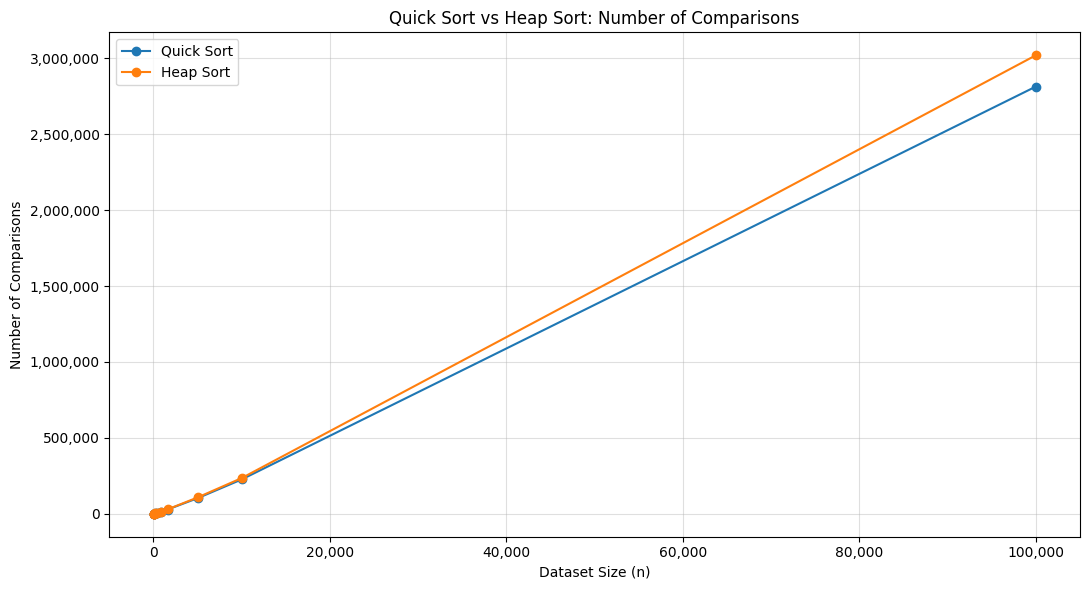

In [61]:
plt.figure(figsize=(11, 6))
plt.plot(part_b_size_df["Dataset Size (n)"], part_b_size_df["Quick Sort Comparisons"], marker="o", label="Quick Sort")
plt.plot(part_b_size_df["Dataset Size (n)"], part_b_size_df["Heap Sort Comparisons"], marker="o", label="Heap Sort")
plt.xlabel("Dataset Size (n)")
plt.ylabel("Number of Comparisons")
plt.title("Quick Sort vs Heap Sort: Number of Comparisons")
plt.legend()
plt.grid(True, alpha=0.4)

ax = plt.gca()
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, position: f"{value:,.0f}"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, position: f"{value:,.0f}"))

plt.tight_layout()
plt.show()

The linear-scale graph shows the absolute comparison counts of both algorithms.

Because the comparison counts cover a large range, a log-log graph is used next to make both growth patterns easier to compare.

### **B4.2 Log-Log Comparison**

A log-log graph is used because the dataset sizes and comparison counts cover large ranges.

The logarithmic scales make the growth patterns of Quick Sort and Heap Sort easier to compare without changing the underlying results.

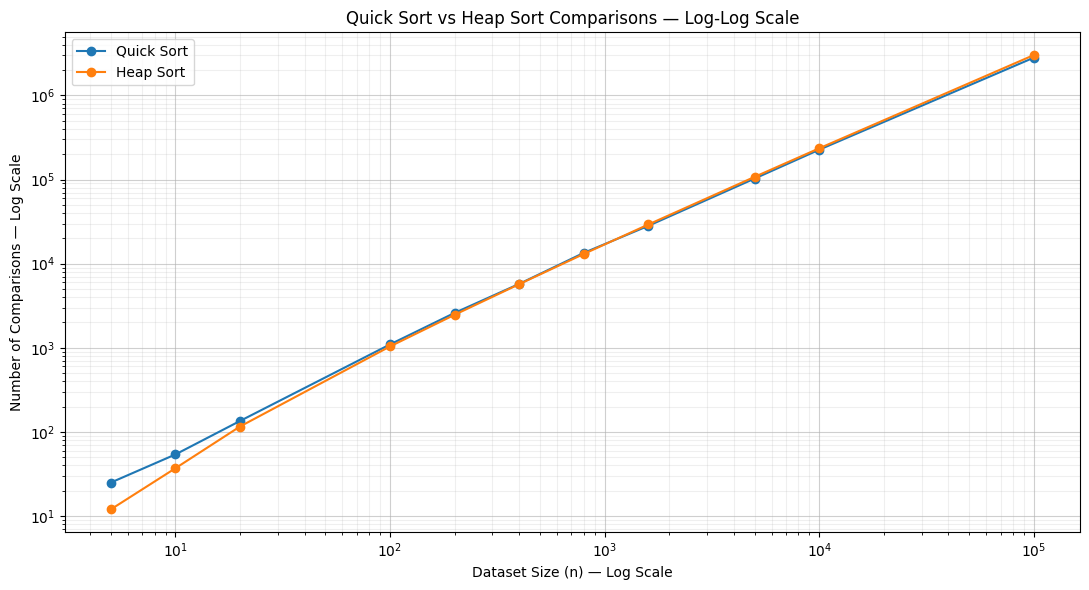

In [62]:
plt.figure(figsize=(11, 6))
plt.plot(part_b_size_df["Dataset Size (n)"], part_b_size_df["Quick Sort Comparisons"], marker="o", label="Quick Sort")
plt.plot(part_b_size_df["Dataset Size (n)"], part_b_size_df["Heap Sort Comparisons"], marker="o", label="Heap Sort")

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Dataset Size (n) — Log Scale")
plt.ylabel("Number of Comparisons — Log Scale")
plt.title("Quick Sort vs Heap Sort Comparisons — Log-Log Scale")

plt.legend()
plt.grid(True, which="major", alpha=0.6)
plt.grid(True, which="minor", alpha=0.2)

plt.tight_layout()
plt.show()

The log-log graph makes both comparison-growth trends visible on the same scale.

However, the graph alone does not confirm the exact growth rate. Therefore, the comparison counts are normalized by \(n\log_2 n\) in the next section.

In [63]:
row_5000 = part_b_size_df[part_b_size_df["Dataset Size (n)"] == 5000].iloc[0]
row_10000 = part_b_size_df[part_b_size_df["Dataset Size (n)"] == 10000].iloc[0]
row_100000 = part_b_size_df[part_b_size_df["Dataset Size (n)"] == 100000].iloc[0]

quick_doubling_growth = row_10000["Quick Sort Comparisons"] / row_5000["Quick Sort Comparisons"]
heap_doubling_growth = row_10000["Heap Sort Comparisons"] / row_5000["Heap Sort Comparisons"]
comparison_ratio_100000 = row_100000["Quick Sort Comparisons"] / row_100000["Heap Sort Comparisons"]

print("Quick Sort growth from 5,000 to 10,000:", round(quick_doubling_growth, 3), "times")
print("Heap Sort growth from 5,000 to 10,000:", round(heap_doubling_growth, 3), "times")
print("Quick ÷ Heap comparison ratio at n = 100,000:", round(comparison_ratio_100000, 3))

Quick Sort growth from 5,000 to 10,000: 2.203 times
Heap Sort growth from 5,000 to 10,000: 2.186 times
Quick ÷ Heap comparison ratio at n = 100,000: 0.932


### **B4.3 Normalized Comparison Counts**

The comparison counts are divided by $n\log_2 n$ to examine how closely the observed growth follows $O(n\log n)$.

- A relatively stable normalized value suggests growth close to $n\log n$.
- A noticeably increasing value suggests growth faster than $n\log n$.

This provides additional empirical evidence but does not prove the exact time complexity.

In [64]:
quick_heap_normalized_df = part_b_size_df.copy()

n = quick_heap_normalized_df["Dataset Size (n)"]
quick_heap_normalized_df["Quick / (n log₂ n)"] = quick_heap_normalized_df["Quick Sort Comparisons"] / (n * np.log2(n))
quick_heap_normalized_df["Heap / (n log₂ n)"] = quick_heap_normalized_df["Heap Sort Comparisons"] / (n * np.log2(n))

quick_heap_normalized_df[["Dataset Size (n)", "Quick / (n log₂ n)", "Heap / (n log₂ n)"]].round(4)

,Dataset Size (n),Quick / (n log₂ n),Heap / (n log₂ n)
0,5,2.1534,1.0336
1,10,1.6256,1.1138
2,20,1.5618,1.3420
3,100,1.6511,1.5623
4,200,1.7014,1.6150
5,400,1.6642,1.6515
6,800,1.7427,1.6915
7,1600,1.6561,1.7184
8,5000,1.6731,1.7519
9,10000,1.7042,1.7706


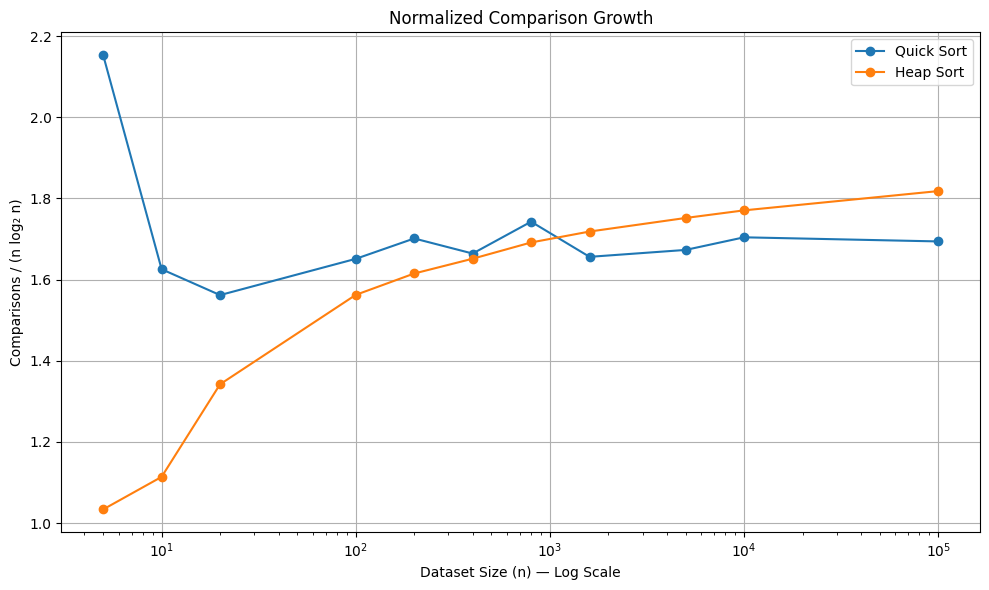

In [65]:
plt.figure(figsize=(10, 6))

plt.plot(
    quick_heap_normalized_df["Dataset Size (n)"],
    quick_heap_normalized_df["Quick / (n log₂ n)"],
    marker="o",
    label="Quick Sort"
)

plt.plot(
    quick_heap_normalized_df["Dataset Size (n)"],
    quick_heap_normalized_df["Heap / (n log₂ n)"],
    marker="o",
    label="Heap Sort"
)

plt.xscale("log")

plt.xlabel("Dataset Size (n) — Log Scale")
plt.ylabel("Comparisons / (n log₂ n)")
plt.title("Normalized Comparison Growth")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### **B4.4 Analysis of Growth Rate**

The linear-scale and log-log graphs show that the comparison counts of Quick Sort and Heap Sort increased at similar rates as the dataset size increased. Unlike the large difference observed between Bubble Sort and Merge Sort in Part A, the two curves remain relatively close, because both algorithms showed approximately $O(n \log n)$ behaviour on the tested random inputs.

A closer look at the comparison ratio (Quick ÷ Heap) shows that the relationship between the two algorithms is not constant — it shifts as $n$ grows, and the two ends of the table point to different explanations.

#### **Small Datasets: Fixed Overhead Dominates**

For the smallest dataset, Quick Sort made more comparisons than Heap Sort. At $n = 5$, the comparison ratio was approximately `2.083`, meaning Quick Sort performed roughly twice as many comparisons.

This is because every Quick Sort partition performs **three additional comparisons during median-of-three pivot selection**. When $n$ is small, this fixed overhead makes up a large proportion of the total work, so it dominates the comparison count. As $n$ increases, this overhead becomes proportionally smaller, and the ratio steadily falls — from `2.083` at $n=5$ to `1.057` at $n=100$ to `1.008` at $n=400$.

#### **The Crossover Point**

In this particular benchmark, the first observed crossover occurred between $n=800$ and $n=1,600$, where the Quick-to-Heap comparison ratio changed from `1.030` to `0.964`. For the remaining tested sizes, Quick Sort made fewer comparisons. However, this should not be treated as a universal threshold because Quick Sort's comparison count depends on the partition balance produced by the specific input.

#### **Large Datasets: Doubling Behaviour**

When the dataset size doubled from 5,000 to 10,000:

- **Quick Sort** comparisons increased from `102,794` to `226,451`, approximately **2.20 times**.
- **Heap Sort** comparisons increased from `107,632` to `235,275`, approximately **2.19 times**.

For an $O(n \log n)$ algorithm, doubling $n$ is expected to increase the amount of work by slightly more than two times, since $\log n$ also grows. Both observed increases are consistent with this expectation.

#### **Normalized Comparison Counts**

Dividing each comparison count by $n \log_2 n$ gives a more direct test of $O(n \log n)$ behaviour: if growth is truly $O(n \log n)$, this normalized value should stay roughly stable as $n$ increases rather than trending upward.

At $n = 100{,}000$:

- Quick Sort: `1.6941`
- Heap Sort: `1.8181`

Both values stay within a similar, bounded range at the largest tested size, which supports approximately $O(n \log n)$ behaviour for both algorithms on these random datasets.

#### **Comparison at the Largest Dataset**

| Algorithm | Comparisons | Runtime |
|---|---:|---:|
| **Quick Sort** | `2,813,769` | `0.7466 s` |
| **Heap Sort** | `3,019,828` | `1.0420 s` |

At $n = 100{,}000$, the comparison ratio was approximately `0.932`, meaning Quick Sort made about **6.8% fewer comparisons** than Heap Sort, and completed in roughly 28% less time.

#### **Why the Ratio Fluctuates**

Even past the crossover point, the exact ratio is not perfectly stable, because the two algorithms arrive at their comparison counts through different mechanisms:

- **Quick Sort's** comparison count depends on how balanced the partitions are at each recursive step, which varies with the specific values chosen as pivots.
- **Heap Sort** follows a fixed heap-building and extraction process, so its comparison count is more consistent for a given $n$.

This difference in mechanism is also why their *theoretical* guarantees diverge even though their *observed* behaviour is similar here. Heap Sort guarantees $O(n \log n)$ worst-case time under all circumstances, while Quick Sort can still degrade to $O(n^2)$ if repeatedly unbalanced partitions occur. Median-of-three pivot selection reduces this risk for many input arrangements, but it does not eliminate Quick Sort's theoretical worst case.

## **B5. Benchmark on Predefined Test Cases**

### **Purpose of the Benchmark**

The eight predefined test cases are used to examine:

1. how increasing dataset size affects both algorithms on **random inputs**;
2. how the **initial input arrangement and repeated values** affect both algorithms.

For each test case:

- Quick Sort and Heap Sort receive separate copies of the same dataset.
- Both sorted outputs are verified against Python's `sorted()` result.
- Comparison count is recorded as the primary performance measure.
- Runtime is included only as supplementary evidence.

### **B5.1 Overall Predefined Test-Case Results**

The table below presents the comparison counts and runtimes of both algorithms across all eight predefined test cases.

The comparison ratio is calculated as:

Comparison Ratio = Quick Sort Comparisons ÷ Heap Sort Comparisons

- A ratio **greater than 1** means Quick Sort made more comparisons.
- A ratio **below 1** means Quick Sort made fewer comparisons.
- A ratio **equal to 1** means both algorithms made the same number of comparisons.

In [66]:
quick_heap_predefined_results = []

for case_name, original_data in test_cases:
    print(f"Running {case_name}...")

    expected = sorted(original_data)

    # Quick Sort
    quick_data = original_data.copy()

    quick_start = time.perf_counter()
    quick_comparisons = quickSortCount(quick_data)
    quick_time = time.perf_counter() - quick_start

    # Heap Sort
    heap_data = original_data.copy()

    heap_start = time.perf_counter()
    heap_comparisons = heapSortCount(heap_data)
    heap_time = time.perf_counter() - heap_start

    # Confirm correctness
    assert quick_data == expected
    assert heap_data == expected

    quick_heap_predefined_results.append({
        "Test Case": case_name,
        "Dataset Size (n)": len(original_data),
        "Quick Sort Comparisons": quick_comparisons,
        "Heap Sort Comparisons": heap_comparisons,
        "Quick Sort Time (s)": quick_time,
        "Heap Sort Time (s)": heap_time
    })

quick_heap_predefined_df = pd.DataFrame(
    quick_heap_predefined_results
)

quick_heap_predefined_df["Comparison Ratio (Quick ÷ Heap)"] = (
    quick_heap_predefined_df["Quick Sort Comparisons"]
    / quick_heap_predefined_df["Heap Sort Comparisons"]
).round(3)

quick_heap_predefined_df

Running Random Small...
Running Random Medium...
Running Random Big...
Running Already Sorted...
Running Reverse Sorted...
Running All Identical...
Running Few Unique...
Running Almost Sorted...


,Test Case,Dataset Size (n),Quick Sort Comparisons,Heap Sort Comparisons,Quick Sort Time (s),Heap Sort Time (s),Comparison Ratio (Quick ÷ Heap)
0,Random Small,1250,21427,21925,0.004084,0.009214,0.977
1,Random Medium,12500,292264,302468,0.073600,0.092633,0.966
2,Random Big,125000,3614814,3850175,0.812471,1.363340,0.939
3,Already Sorted,1000,38824,17583,0.009554,0.005471,2.208
4,Reverse Sorted,1000,29884,15965,0.004649,0.004976,1.872
5,All Identical,1000,2003,2994,0.000195,0.001449,0.669
6,Few Unique,1000,3937,14177,0.000719,0.004513,0.278
7,Almost Sorted,999,32420,17552,0.006941,0.005897,1.847


In [67]:
assert len(quick_heap_predefined_df) == len(test_cases)

assert quick_heap_predefined_df["Test Case"].tolist() == [
    case_name for case_name, _ in test_cases
]

print("All eight predefined test cases were benchmarked successfully.")

All eight predefined test cases were benchmarked successfully.


### **B5.2 Effect of Dataset Size on Random Inputs**

The three predefined random datasets increase by a factor of ten at each stage:

| Dataset | Size |
|---|---:|
| **Random Small** | n = 1,250 |
| **Random Medium** | n = 12,500 |
| **Random Big** | n = 125,000 |

A log-log graph is used because both the dataset sizes and comparison counts cover large ranges.

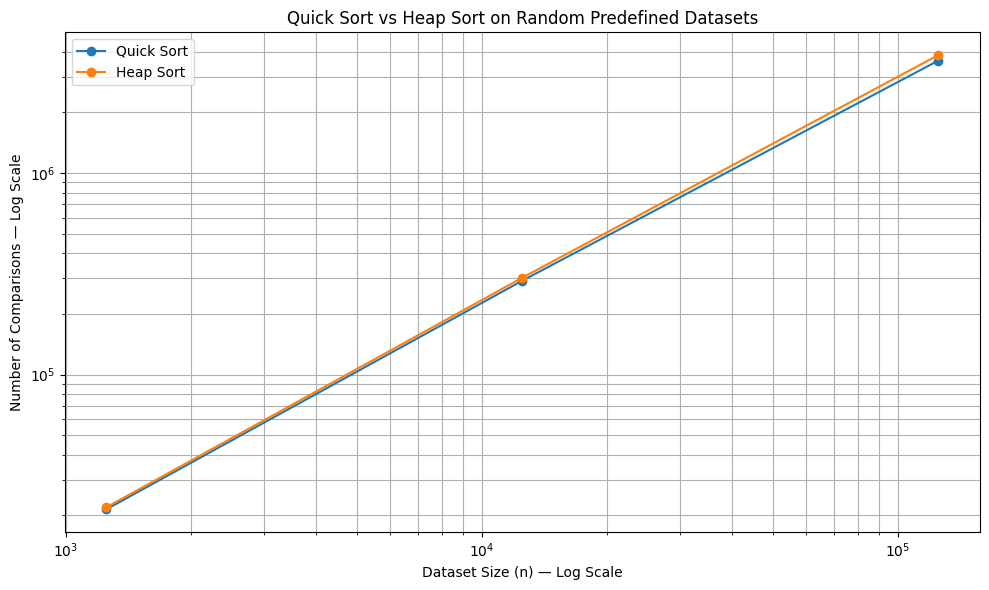

In [68]:
quick_heap_random_df = quick_heap_predefined_df[
    quick_heap_predefined_df["Test Case"].isin([
        "Random Small",
        "Random Medium",
        "Random Big"
    ])
].copy()

plt.figure(figsize=(10, 6))

plt.plot(
    quick_heap_random_df["Dataset Size (n)"],
    quick_heap_random_df["Quick Sort Comparisons"],
    marker="o",
    label="Quick Sort"
)

plt.plot(
    quick_heap_random_df["Dataset Size (n)"],
    quick_heap_random_df["Heap Sort Comparisons"],
    marker="o",
    label="Heap Sort"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Dataset Size (n) — Log Scale")
plt.ylabel("Number of Comparisons — Log Scale")
plt.title("Quick Sort vs Heap Sort on Random Predefined Datasets")
plt.legend()
plt.grid(True, which="both")
plt.tight_layout()
plt.show()

#### **Analysis of Random Input Growth**

The log-log graph shows that Quick Sort and Heap Sort followed similar growth patterns as the random dataset size increased. This is consistent with approximately $O(n \log n)$ behaviour for both algorithms on the tested random inputs.

From **Random Small** to **Random Big**, the dataset size increased from 1,250 to 125,000 elements, representing a **100-fold increase**.

For a purely $O(n \log n)$ algorithm, a 100-fold increase in $n$ predicts a comparison-count increase of approximately:

$$
100 \times \frac{\log_2(125{,}000)}{\log_2(1{,}250)} \approx 100 \times \frac{16.93}{10.29} \approx 164.5 \text{ times}
$$

Over the same increase:

- **Quick Sort** comparisons increased from `21,427` to `3,614,814`, approximately **168.70 times**.
- **Heap Sort** comparisons increased from `21,925` to `3,850,175`, approximately **175.61 times**.

Both observed growth factors are reasonably close to the predicted $164.5×$ scaling. The remaining differences reflect implementation-specific constant factors and, for Quick Sort, variation in partition balance.

Quick Sort made fewer comparisons for all three predefined random datasets. The Quick-to-Heap comparison ratio decreased from `0.977` for Random Small to `0.939` for Random Big. At Random Big, Quick Sort therefore made approximately **6.1% fewer comparisons** than Heap Sort.

The two lines remain relatively close because both algorithms showed approximately $O(n \log n)$ growth on these random inputs. However, the exact Quick Sort comparison count depends on how evenly the median-of-three pivots divide the data, while Heap Sort follows a more fixed heap-construction and extraction process.

For Random Big, Quick Sort took approximately `0.812` seconds, while Heap Sort took approximately `1.363` seconds in this execution. Runtime is hardware-dependent, so comparison count remains the primary empirical measure, while runtime provides supplementary evidence.

Although both algorithms demonstrated approximately $O(n \log n)$ behaviour in these experiments, their theoretical guarantees remain different. Heap Sort guarantees $O(n \log n)$ worst-case time, while Quick Sort can still degrade to $O(n^2)$ if repeatedly unbalanced partitions occur.

### **B5.3 Effect of Input Arrangement**

Five structured test cases are used to examine how the initial arrangement and repeated values affect both algorithms:

- **Already Sorted**
- **Reverse Sorted**
- **All Identical**
- **Few Unique**
- **Almost Sorted**

Most datasets contain approximately **1,000 elements**, making their comparison counts directly comparable.

> **Note:** The `Almost Sorted` dataset contains `999` elements because this is the size of the predefined list.

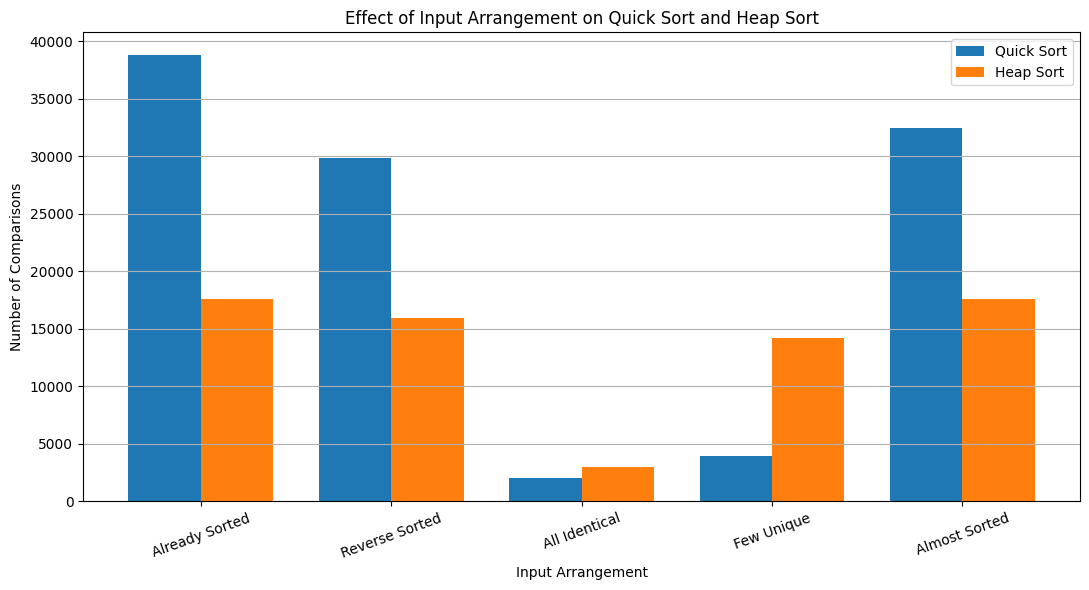

In [69]:
quick_heap_structured_cases = [
    "Already Sorted",
    "Reverse Sorted",
    "All Identical",
    "Few Unique",
    "Almost Sorted"
]

quick_heap_structured_df = (
    quick_heap_predefined_df[
        quick_heap_predefined_df["Test Case"].isin(
            quick_heap_structured_cases
        )
    ]
    .set_index("Test Case")
    .loc[quick_heap_structured_cases]
    .reset_index()
)

x = np.arange(len(quick_heap_structured_df))
width = 0.38

plt.figure(figsize=(11, 6))

plt.bar(
    x - width / 2,
    quick_heap_structured_df["Quick Sort Comparisons"],
    width,
    label="Quick Sort"
)

plt.bar(
    x + width / 2,
    quick_heap_structured_df["Heap Sort Comparisons"],
    width,
    label="Heap Sort"
)

plt.xticks(
    x,
    quick_heap_structured_df["Test Case"],
    rotation=20
)

plt.xlabel("Input Arrangement")
plt.ylabel("Number of Comparisons")
plt.title("Effect of Input Arrangement on Quick Sort and Heap Sort")
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.show()

#### **Analysis of Input Arrangement**

Quick Sort showed a strong response to both the **initial arrangement** and the **number of duplicate values**.

| Input Arrangement | Quick Sort | Heap Sort | Lower Comparison Count |
|---|---:|---:|---|
| **Already Sorted** | `38,824` | `17,583` | Heap Sort |
| **Reverse Sorted** | `29,884` | `15,965` | Heap Sort |
| **All Identical** | `2,003` | `2,994` | Quick Sort |
| **Few Unique** | `3,937` | `14,177` | Quick Sort |
| **Almost Sorted** | `32,420` | `17,552` | Heap Sort |

**Quick Sort** required substantially more comparisons for the Already Sorted, Reverse Sorted, and Almost Sorted inputs. Median-of-three pivot selection reduces the risk of selecting an extreme pivot, but it does not guarantee balanced partitions at every recursive level — a structured input can still produce a run of uneven splits that median-of-three doesn't catch.

In contrast, three-way partitioning performed especially well when many duplicate values were present. For **All Identical**, all 1,000 values entered the equal-to-pivot region during the first partition, so no further recursive sorting was required. The comparison count reduces to a fixed **3 comparisons for median-of-three pivot selection**. For each of the 1,000 elements, the partition first evaluates < pivot and then > pivot. Since both conditions are false for an equal value, each element performs two partition comparisons. Together with the three median-of-three comparisons:

$$
3 + 2(1000) = 2{,}003
$$

For **Few Unique**, Quick Sort made only `3,937` comparisons compared with `14,177` for Heap Sort — approximately **72.2% fewer comparisons**. The same three-way partitioning advantage applies, though less completely than in the All Identical case, since not every value collapses into a single equal-to-pivot region.

**Heap Sort** also responds to the input values because the number of heapify steps can vary depending on how far an element moves through the heap. However, its comparison counts were less sensitive than this Quick Sort implementation on the tested ordered and almost-ordered inputs. Its fixed build-and-extract structure and guaranteed $O(n logn)$ worst-case time make its overall behaviour more predictable. In these tests, Heap Sort's comparison counts varied much less across Already Sorted (`17,583`), Reverse Sorted (`15,965`), and Almost Sorted (`17,552`). Input arrangement can still affect heapify behaviour, but its effect was smaller than the effect of partition balance on this Quick Sort implementation.

Overall, neither algorithm was best for every structured input. Quick Sort benefited strongly from **duplicate-heavy data**, while Heap Sort performed better on the **sorted, reverse-sorted, and almost-sorted inputs** tested. This reinforces the earlier finding from the random-input tests: both algorithms showed approximately O(nlogn) growth on the tested random inputs, but their comparison counts diverge substantially once the input has exploitable structure — favourable for one algorithm's mechanism and unfavourable for the other's.

### **B6. Theoretical Comparison and Conclusion**

#### **Theoretical Comparison**

| Property | Quick Sort Used in This Experiment | Heap Sort Used in This Experiment |
|---|---|---|
| **General strategy** | Median-of-three pivot with in-place three-way partitioning | In-place binary max heap with iterative `heapify` |
| **Implementation-specific special case** | $O(n)$ for all-identical data because three-way partitioning handles all equal values in one partition | Approximately $O(n)$ key-comparison behaviour for all-identical data because each `heapify` terminates immediately |
| **Average-case time** | $O(n \log n)$ | $O(n \log n)$ |
| **Worst-case time** | $O(n^2)$ | $O(n \log n)$ |
| **Auxiliary space** | Average $O(\log n)$; worst $O(n)$ recursion stack | $O(1)$ |
| **In-place** | Yes for the data array, but recursion uses stack space | Yes |
| **Stable** | No | No |
| **Main advantage** | Strong practical performance and efficient handling of duplicates | Guaranteed worst-case time and constant auxiliary space |
| **Main limitation** | Performance depends on pivot quality and partition balance | May require more comparisons on some inputs and does not exploit duplicate-heavy data as effectively as this three-way Quick Sort |

#### **Empirical Findings**

On the required random datasets, Quick Sort and Heap Sort both demonstrated growth consistent with $O(n \log n)$.

At n = 100,000:

| Algorithm | Comparisons | Runtime |
|---|---:|---:|
| **Quick Sort** | `2,813,769` | `0.7466 s` |
| **Heap Sort** | `3,019,828` | `1.0420 s` |

Quick Sort therefore made approximately **6.8% fewer comparisons** for the largest required dataset.

The normalized comparison counts also remained relatively stable for larger values of n, providing further empirical support for approximately $O(n \log n)$ growth on the tested random inputs.

The predefined random cases produced a similar pattern. Quick Sort made fewer comparisons than Heap Sort for **Random Small, Random Medium, and Random Big**, and also completed the largest predefined random dataset more quickly in the recorded execution.

However, Quick Sort was more sensitive to input characteristics. It made substantially more comparisons than Heap Sort on the **Already Sorted, Reverse Sorted, and Almost Sorted** datasets. Median-of-three pivot selection reduces the risk of selecting an extreme endpoint as the pivot, but it does not guarantee balanced partitions at every recursive level.

Three-way partitioning gave Quick Sort a major advantage when repeated values were present. For the **Few Unique** dataset, Quick Sort made only `3,937` comparisons compared with `14,177` for Heap Sort. Values equal to the pivot were grouped together and excluded from later recursive calls.

Heap Sort provides a more predictable worst-case guarantee because its time complexity remains $O(n \log n)$ regardless of the input arrangement. Its iterative `heapify` implementation also requires only $O(1)$ auxiliary space.

#### **Conclusion**

Quick Sort is more suitable when **strong average practical performance and efficient handling of duplicate values** are important. However, its performance depends on pivot selection and partition balance, and its theoretical worst case remains $O(n^2)$.

Heap Sort is more suitable when **predictable worst-case performance and constant auxiliary space** are priorities.

Therefore, neither algorithm is universally better. The experimental results show that algorithm selection should consider the **input characteristics, scalability, worst-case guarantee, and memory requirements**.

The selected algorithms satisfy the Part B requirement because they differ in both **worst-case time complexity** and **auxiliary-space complexity**.

### **B7. Experimental Limitations**

The results should be interpreted with the following limitations:

1. **One generated dataset per size**  
   A fixed random seed was used to make the benchmark reproducible. However, each required dataset size was represented by only one generated random dataset. Different random seeds may produce different Quick Sort partition balances and slightly different comparison counts.

2. **Implementation-specific results**  
   The Quick Sort results apply specifically to the **median-of-three, three-way partitioning** implementation used in this notebook. Different pivot-selection or partitioning strategies may produce different results.

   The Heap Sort results apply specifically to the **iterative max-heap** implementation used here.

3. **Quick Sort worst case was not deliberately constructed**  
   None of the supplied test cases forced the theoretical $O(n^2)$ behaviour of this Quick Sort implementation. Adversarial inputs that consistently defeat median-of-three pivot selection would need to be deliberately constructed to observe this behaviour. Therefore, the absence of quadratic growth in the experimental graphs does not remove its theoretical worst case.

4. **Runtime depends on the execution environment**  
   Runtime was measured once per dataset and may be affected by processor performance, background processes, and system load. Therefore, comparison count is treated as the primary empirical measure.

5. **Comparison count does not measure every operation**  
   The counter records only comparisons between dataset values. Swaps, assignments, index checks, and loop conditions are excluded, so comparison count does not represent the total amount of work performed by an algorithm.

Overall, these experiments demonstrate how the selected implementations behaved on the tested datasets and provide empirical evidence consistent with their theoretical time and space complexity characteristics.

# **Individual Investigation: In-Place Sorting**

## **Name: Thawdar Lin Wai**


## **1. What Is In-Place Sorting?**

A sorting algorithm is considered **in-place** when it rearranges elements within the original data structure while using only a constant amount of auxiliary storage, $O(1)$. This does not mean that no additional memory is used; a fixed number of variables such as indices or temporary values may still be required.

Examples of in-place sorting algorithms include **Bubble Sort** and an iterative implementation of **Heap Sort**. In contrast, the standard array implementation of **Merge Sort** is typically considered out-of-place because it creates temporary sublists during the merge process.

| Algorithm | Typical Auxiliary Space | In-Place? |
| --- | ---: | --- |
| **Bubble Sort** | $O(1)$ | Yes |
| **Heap Sort (iterative)** | $O(1)$ | Yes |
| **Standard Merge Sort** | $O(n)$ | No |

Standard Merge Sort requires $O(n)$ auxiliary space because its temporary left and right sublists grow with the input size. This makes Merge Sort a useful case study for demonstrating how a traditionally out-of-place sorting algorithm can be modified to reduce its memory requirement.

In this case study, a **bottom-up, shift-based Merge Sort variant** is used. Instead of creating temporary sublists, neighbouring sorted sections are merged directly within the original list by shifting elements when necessary. This reduces the auxiliary-space requirement to $O(1)$ for the tested implementation.

The case study therefore demonstrates the main advantage of in-place sorting—**lower auxiliary memory usage**—while also examining the trade-off introduced by additional element movements and runtime.

## **2. Case Study: Making Merge Sort In-Place**

Two implementations are compared:

1. **Standard Merge Sort** - recursive and creates temporary `leftHalf` and `rightHalf` lists while merging.
2. **Shift-Based In-Place Merge Sort** - bottom-up and merges neighbouring sorted sections directly inside the original list.

The case study measures **comparisons, element movements, peak auxiliary memory, and runtime**. This allows the change in space usage to be evaluated together with its practical time cost.

### **2.1 Standard Merge Sort (Out-of-Place Baseline)**

In [2]:
def standardMergeSortMetrics(l, stats=None):
    """
    Standard Merge Sort using temporary left and right sublists.

    Metrics:
    - comparisons: comparisons between two dataset values
    - movements: writes of dataset values back into the list
    """

    if stats is None:
        stats = {
            "comparisons": 0,
            "movements": 0
        }

    # Base case
    if len(l) <= 1:
        return stats

    # Step 1: Split the list into temporary sublists
    mid = len(l) // 2
    leftHalf = l[:mid]
    rightHalf = l[mid:]

    # Recursively sort both halves
    standardMergeSortMetrics(leftHalf, stats)
    standardMergeSortMetrics(rightHalf, stats)

    leftIndex = 0
    rightIndex = 0
    mergeIndex = 0

    # Step 2: Merge the two sorted halves
    while (
        leftIndex < len(leftHalf)
        and rightIndex < len(rightHalf)
    ):
        # One comparison between two dataset values
        stats["comparisons"] += 1

        if leftHalf[leftIndex] <= rightHalf[rightIndex]:
            l[mergeIndex] = leftHalf[leftIndex]
            leftIndex += 1
        else:
            l[mergeIndex] = rightHalf[rightIndex]
            rightIndex += 1

        # One dataset value is written into the merged list
        stats["movements"] += 1
        mergeIndex += 1

    # Copy remaining values from the left half
    while leftIndex < len(leftHalf):
        l[mergeIndex] = leftHalf[leftIndex]

        stats["movements"] += 1

        leftIndex += 1
        mergeIndex += 1

    # Copy remaining values from the right half
    while rightIndex < len(rightHalf):
        l[mergeIndex] = rightHalf[rightIndex]

        stats["movements"] += 1

        rightIndex += 1
        mergeIndex += 1

    return stats

### **2.2 Shift-Based In-Place Merge Sort**

Instead of creating:

```python
leftHalf = l[:mid]
rightHalf = l[mid:]
```

the in-place version merges two neighbouring sorted sections inside the same list.

For example:

`[2, 5, 8 | 1, 4, 7]`

Since `1 < 2`, `1` must move before the left section. The intervening values are shifted right:

`[1, 2, 5, 8, 4, 7]`

This removes the temporary sublists, but a value that belongs far to the left may require many shifts. Therefore, the expected trade-off is **less auxiliary memory but potentially more data movement and runtime**.

In [3]:
def inPlaceMerge(l, left, mid, right, stats):
    """
    Merge two neighbouring sorted sections directly within l.

    Left section:
        l[left : mid + 1]

    Right section:
        l[mid + 1 : right + 1]

    No temporary left/right lists are created.
    """

    i = left
    j = mid + 1

    # Continue while both sorted sections still contain values
    while i <= mid and j <= right:

        # Compare one value from each section
        stats["comparisons"] += 1

        # Value already appears in the correct relative order
        if l[i] <= l[j]:
            i += 1

        else:
            # l[j] belongs before l[i]
            value = l[j]
            index = j

            # Shift values one position to the right
            while index > i:
                l[index] = l[index - 1]
                stats["movements"] += 1
                index -= 1

            # Insert the displaced value
            l[i] = value
            stats["movements"] += 1

            # Section boundaries have changed after insertion
            i += 1
            mid += 1
            j += 1

In [4]:
def inPlaceMergeSortMetrics(l):
    """
    Bottom-up Merge Sort using in-place merging.

    Metrics:
    - comparisons: comparisons between two dataset values
    - movements: writes of dataset values during in-place merging
    """

    stats = {
        "comparisons": 0,
        "movements": 0
    }

    n = len(l)

    # Initially, each individual value is a sorted section of size 1
    width = 1

    while width < n:

        left = 0

        # Merge neighbouring sections of the current width
        while left < n - 1:

            mid = min(left + width - 1, n - 1)
            right = min(left + (2 * width) - 1, n - 1)

            # A right section exists only when mid < right
            if mid < right:
                inPlaceMerge(
                    l,
                    left,
                    mid,
                    right,
                    stats
                )

            left += 2 * width

        # Each completed level doubles the sorted section size
        width *= 2

    return stats

In [5]:
# Small correctness comparison

test_data = [8, 3, 6, 1, 7, 2, 5, 4]

# Separate copies ensure a fair comparison
standard_output = test_data.copy()
inplace_output = test_data.copy()

standard_stats = standardMergeSortMetrics(standard_output)
inplace_stats = inPlaceMergeSortMetrics(inplace_output)

expected = sorted(test_data)

print("Original:             ", test_data)
print("Expected:             ", expected)
print()

print("Standard Merge Sort:  ", standard_output)
print("In-Place Merge Sort:  ", inplace_output)
print()

print("Standard correct:     ", standard_output == expected)
print("In-place correct:     ", inplace_output == expected)
print()

print("Standard comparisons: ", standard_stats["comparisons"])
print("In-place comparisons: ", inplace_stats["comparisons"])
print()

print("Standard movements:   ", standard_stats["movements"])
print("In-place movements:   ", inplace_stats["movements"])

Original:              [8, 3, 6, 1, 7, 2, 5, 4]
Expected:              [1, 2, 3, 4, 5, 6, 7, 8]

Standard Merge Sort:   [1, 2, 3, 4, 5, 6, 7, 8]
In-Place Merge Sort:   [1, 2, 3, 4, 5, 6, 7, 8]

Standard correct:      True
In-place correct:      True

Standard comparisons:  17
In-place comparisons:  17

Standard movements:    24
In-place movements:    29


### **2.3 Initial Comparison**

Both implementations correctly sort the same eight-value test list.

| Metric | Standard | In-Place |
| --- | ---: | ---: |
| **Comparisons** | 17 | 17 |
| **Movements** | 24 | 29 |

For this test, the comparison count is identical, but the in-place version performs more writes because inserting a value from the right section may require several shifts. The larger experiments below test whether this difference grows with dataset size and input arrangement.

## **3. Correctness Validation**

Before benchmarking, both implementations are tested on empty, single-value, sorted, reverse-sorted, duplicate, identical, mixed-sign, odd-length, and random lists. Each receives a separate copy of the same input, and its result must equal Python's `sorted()` output.

In [6]:
# Correctness validation across different input conditions

validation_cases = [
    ("Empty", []),
    ("Single Value", [5]),
    ("Already Sorted", [1, 2, 3, 4, 5, 6, 7, 8]),
    ("Reverse Sorted", [8, 7, 6, 5, 4, 3, 2, 1]),
    ("Duplicates", [4, 2, 4, 1, 3, 2, 1, 4]),
    ("All Identical", [7, 7, 7, 7, 7, 7, 7, 7]),
    ("Negative and Positive", [3, -2, 5, -8, 0, 1, -1]),
    ("Odd Length", [9, 3, 7, 1, 8, 2, 6]),
    ("Random Order", [12, 4, 19, 1, 8, 15, 3, 10, 6])
]

validation_results = []

for case_name, original_data in validation_cases:

    standard_data = original_data.copy()
    inplace_data = original_data.copy()

    standardMergeSortMetrics(standard_data)
    inPlaceMergeSortMetrics(inplace_data)

    expected = sorted(original_data)

    validation_results.append({
        "Test Case": case_name,
        "Standard Merge Sort": standard_data == expected,
        "In-Place Merge Sort": inplace_data == expected
    })

validation_df = pd.DataFrame(validation_results)

validation_df

,Test Case,Standard Merge Sort,In-Place Merge Sort
0,Empty,True,True
1,Single Value,True,True
2,Already Sorted,True,True
3,Reverse Sorted,True,True
4,Duplicates,True,True
5,All Identical,True,True
6,Negative and Positive,True,True
7,Odd Length,True,True
8,Random Order,True,True


In [7]:
# Additional randomised correctness validation
import random
random.seed(42)

random_validation_passed = True
failed_case = None

for test_number in range(100):

    size = random.randint(0, 100)

    original_data = [
        random.randint(-1000, 1000)
        for _ in range(size)
    ]

    standard_data = original_data.copy()
    inplace_data = original_data.copy()

    standardMergeSortMetrics(standard_data)
    inPlaceMergeSortMetrics(inplace_data)

    expected = sorted(original_data)

    if (
        standard_data != expected
        or inplace_data != expected
    ):
        random_validation_passed = False
        failed_case = test_number
        break

print("100 random validation tests passed:", random_validation_passed)

if not random_validation_passed:
    print("First failed test:", failed_case)

100 random validation tests passed: True


### **3.1 Correctness Results**

Both implementations passed all designed test cases and **100 additional random tests**. This provides confidence that the following experiments compare valid sorting implementations.

## **4. Experimental Design**

The main operation and runtime experiments use dataset sizes:

`64, 128, 256, 512, 1024, 2048`

Four controlled arrangements are tested:

| Arrangement | Purpose |
| --- | --- |
| **Already Sorted** | Requires little or no shifting |
| **Almost Sorted** | Tests limited disorder |
| **Random** | Represents an unstructured input |
| **Reverse Sorted** | Produces extensive shifting |

Both variants receive copies of the same dataset, use the same metric definitions, and are checked for correctness. A fixed random seed makes generated inputs reproducible. Operation counts, memory, and runtime are measured separately so the time-space trade-off can be interpreted clearly.

In [8]:
# Controlled dataset generator for the in-place case study

INPLACE_SEED = 42


def generateInPlaceTestData(n, arrangement, seed=INPLACE_SEED):
    """
    Generate controlled datasets for the Standard vs In-Place
    Merge Sort investigation.
    """

    if arrangement == "Already Sorted":
        return list(range(n))

    elif arrangement == "Reverse Sorted":
        return list(range(n - 1, -1, -1))

    elif arrangement == "Random":
        rng = random.Random(seed + n)
        data = list(range(n))
        rng.shuffle(data)
        return data

    elif arrangement == "Almost Sorted":
        data = list(range(n))

        rng = random.Random(seed + n)

        # Swap approximately 5% of neighbouring pairs
        number_of_swaps = max(1, n // 20)

        possible_indices = list(range(n - 1))
        rng.shuffle(possible_indices)

        # Prevent overlapping adjacent swaps
        used_indices = set()
        swaps_made = 0

        for i in possible_indices:
            if (
                i not in used_indices
                and i + 1 not in used_indices
            ):
                data[i], data[i + 1] = data[i + 1], data[i]

                used_indices.add(i)
                used_indices.add(i + 1)

                swaps_made += 1

                if swaps_made == number_of_swaps:
                    break

        return data

    else:
        raise ValueError("Unknown input arrangement")

## **5. Experiment 1: Comparisons and Element Movements**

Both variants are tested across all six sizes and four input arrangements. **Comparisons** record order decisions, while **movements** record writes that reposition values during merging.

Movement definition:
Count one movement whenever a dataset value is written
to a list position during the merge operation.

Temporary-list creation in Standard Merge Sort is NOT
counted here because auxiliary storage is measured separately.

In [34]:
# Experiment 1: Comparison and element-movement benchmark

inplace_sizes = [
    64,
    128,
    256,
    512,
    1024,
    2048
]

inplace_arrangements = [
    "Already Sorted",
    "Reverse Sorted",
    "Random",
    "Almost Sorted"
]

inplace_operation_results = []

for arrangement in inplace_arrangements:

    print(f"Running arrangement: {arrangement}")

    for n in inplace_sizes:

        # Generate one controlled dataset
        original_data = generateInPlaceTestData(
            n,
            arrangement
        )

        expected = sorted(original_data)

        # Give each implementation a separate copy
        standard_data = original_data.copy()
        inplace_data = original_data.copy()

        # Run Standard Merge Sort
        standard_stats = standardMergeSortMetrics(
            standard_data
        )

        # Run In-Place Merge Sort
        inplace_stats = inPlaceMergeSortMetrics(
            inplace_data
        )

        # Correctness checks
        standard_correct = standard_data == expected
        inplace_correct = inplace_data == expected

        if not standard_correct or not inplace_correct:
            raise ValueError(
                f"Incorrect sorting result for "
                f"{arrangement}, n={n}"
            )

        # Store Standard Merge Sort result
        inplace_operation_results.append({
            "Input Arrangement": arrangement,
            "n": n,
            "Algorithm": "Standard Merge Sort",
            "Comparisons": standard_stats["comparisons"],
            "Movements": standard_stats["movements"]
        })

        # Store In-Place Merge Sort result
        inplace_operation_results.append({
            "Input Arrangement": arrangement,
            "n": n,
            "Algorithm": "In-Place Merge Sort",
            "Comparisons": inplace_stats["comparisons"],
            "Movements": inplace_stats["movements"]
        })

inplace_operation_df = pd.DataFrame(
    inplace_operation_results
)

Running arrangement: Already Sorted
Running arrangement: Reverse Sorted
Running arrangement: Random
Running arrangement: Almost Sorted


In [10]:
inplace_operation_df

,Input Arrangement,n,Algorithm,Comparisons,Movements
0,Already Sorted,64,Standard Merge Sort,192,384
1,Already Sorted,64,In-Place Merge Sort,192,0
2,Already Sorted,128,Standard Merge Sort,448,896
3,Already Sorted,128,In-Place Merge Sort,448,0
4,Already Sorted,256,Standard Merge Sort,1024,2048
5,Already Sorted,256,In-Place Merge Sort,1024,0
6,Already Sorted,512,Standard Merge Sort,2304,4608
7,Already Sorted,512,In-Place Merge Sort,2304,0
8,Already Sorted,1024,Standard Merge Sort,5120,10240
9,Already Sorted,1024,In-Place Merge Sort,5120,0


In [33]:
largest_n_summary = (
    inplace_operation_df[
        inplace_operation_df["n"] == 2048
    ]
    .pivot_table(
        index="Input Arrangement",
        columns="Algorithm",
        values=["Comparisons", "Movements"]
    )
)

largest_n_summary

Comparisons                               Movements  \
Algorithm         In-Place Merge Sort Standard Merge Sort In-Place Merge Sort   
Input Arrangement                                                               
Almost Sorted                 11310.0             11310.0               204.0   
Already Sorted                11264.0             11264.0                 0.0   
Random                        19892.0             19892.0           1055226.0   
Reverse Sorted                11264.0             11264.0           2107392.0   

                                       
Algorithm         Standard Merge Sort  
Input Arrangement                      
Almost Sorted                 22528.0  
Already Sorted                22528.0  
Random                        22528.0  
Reverse Sorted                22528.0

### **5.1 Results at $n=2048$**

| Input Arrangement | Standard Comparisons | In-Place Comparisons | Standard Movements | In-Place Movements |
| --- | ---: | ---: | ---: | ---: |
| **Already Sorted** | 11,264 | 11,264 | 22,528 | 0 |
| **Almost Sorted** | 11,310 | 11,310 | 22,528 | 204 |
| **Random** | 19,892 | 19,892 | 22,528 | 1,055,226 |
| **Reverse Sorted** | 11,264 | 11,264 | 22,528 | 2,107,392 |

For the tested power-of-two datasets, both variants make the same number of comparisons. The difference appears in data movement.

Standard Merge Sort performs $n\log_2 n$ merge writes, so at $n=2048$ it makes $2048\times11=22{,}528$ movements regardless of arrangement. The in-place variant makes almost no movements on ordered data, but **46.84×** as many movements as Standard on Random data and **93.55×** as many on Reverse Sorted data.

For Reverse Sorted data, the large movement count is caused by repeated shifts as values are inserted into earlier positions. This is the main time cost introduced by the shift-based in-place merge.

### **5.2 Operation-Growth Visualisation**

The graphs below show how comparisons and movements grow with $n$. They are plotted separately because movement counts become much larger than comparison counts.

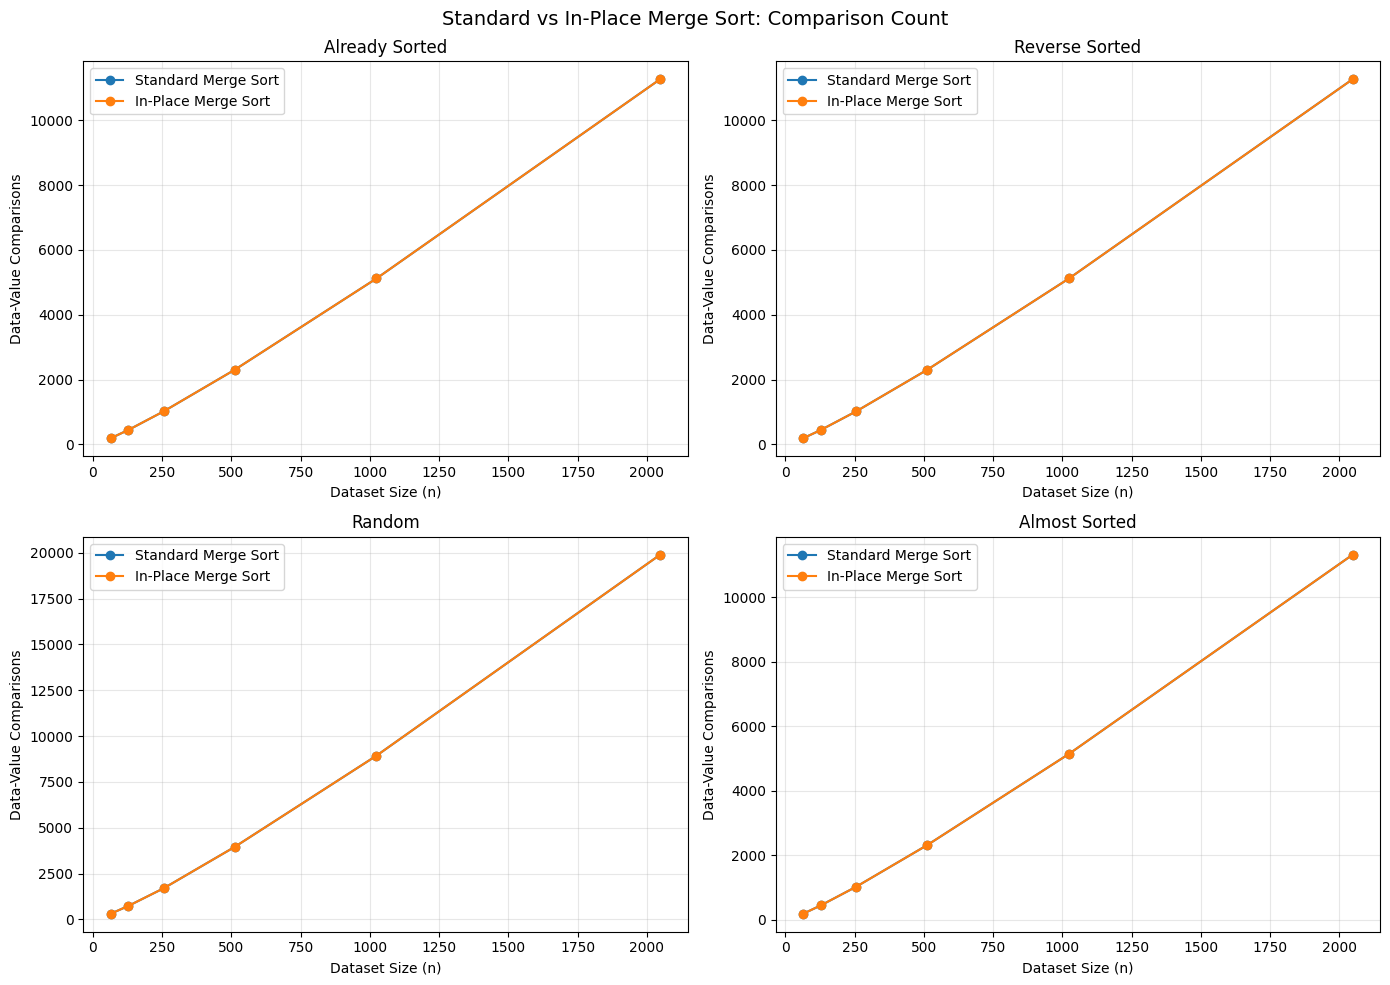

In [11]:
# Comparison-count growth across dataset sizes

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10)
)

axes = axes.flatten()

for ax, arrangement in zip(
    axes,
    inplace_arrangements
):
    subset = inplace_operation_df[
        inplace_operation_df["Input Arrangement"] == arrangement
    ]

    for algorithm in [
        "Standard Merge Sort",
        "In-Place Merge Sort"
    ]:
        algorithm_data = subset[
            subset["Algorithm"] == algorithm
        ]

        ax.plot(
            algorithm_data["n"],
            algorithm_data["Comparisons"],
            marker="o",
            label=algorithm
        )

    ax.set_title(arrangement)
    ax.set_xlabel("Dataset Size (n)")
    ax.set_ylabel("Data-Value Comparisons")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle(
    "Standard vs In-Place Merge Sort: Comparison Count",
    fontsize=14
)

plt.tight_layout()
plt.show()

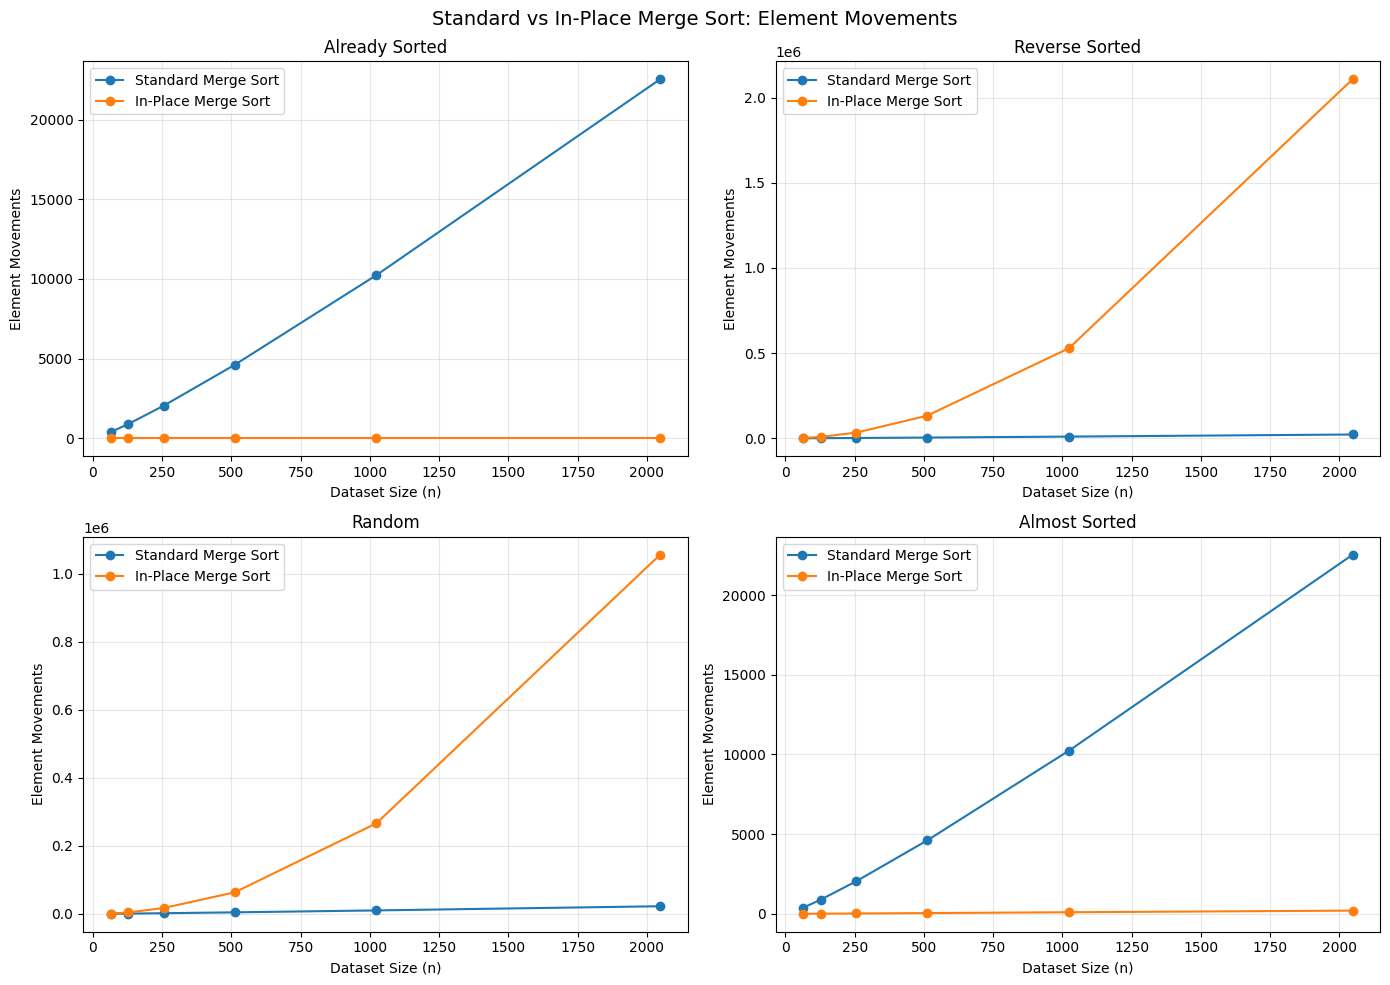

In [12]:
# Element-movement growth across dataset sizes

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10)
)

axes = axes.flatten()

for ax, arrangement in zip(
    axes,
    inplace_arrangements
):
    subset = inplace_operation_df[
        inplace_operation_df["Input Arrangement"] == arrangement
    ]

    for algorithm in [
        "Standard Merge Sort",
        "In-Place Merge Sort"
    ]:
        algorithm_data = subset[
            subset["Algorithm"] == algorithm
        ]

        ax.plot(
            algorithm_data["n"],
            algorithm_data["Movements"],
            marker="o",
            label=algorithm
        )

    ax.set_title(arrangement)
    ax.set_xlabel("Dataset Size (n)")
    ax.set_ylabel("Element Movements")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle(
    "Standard vs In-Place Merge Sort: Element Movements",
    fontsize=14
)

plt.tight_layout()
plt.show()

### **5.3 Analysis of Operation Growth**

For all tested power-of-two datasets, the Standard and In-Place comparison curves overlap. However, their movement behaviour differs strongly.

- **Standard:** movements follow $n\log_2 n$ and are not affected by input arrangement.
- **Already Sorted:** In-Place requires **0 movements** at every tested size.
- **Almost Sorted:** In-Place rises only from **6** to **204** movements.
- **Random:** In-Place rises from **1,140** to **1,055,226** movements.
- **Reverse Sorted:** In-Place rises from **2,208** to **2,107,392** movements.

For Random and Reverse Sorted data, the movement count grows by roughly four times when $n$ doubles, which is consistent with near-quadratic movement growth for this shift-based method. Therefore, the cost of making Merge Sort in-place is highly dependent on how much shifting the input requires.

## **6. Implementations for Memory and Runtime**

The metric-counting versions perform extra counter updates. The following equivalent **non-instrumented** implementations remove those counters and are used for the memory and runtime experiments so that the measurements better reflect the sorting strategies themselves.

In [13]:
def standardMergeSortClean(l):
    if len(l) <= 1:
        return

    mid = len(l) // 2

    leftHalf = l[:mid]
    rightHalf = l[mid:]

    standardMergeSortClean(leftHalf)
    standardMergeSortClean(rightHalf)

    leftIndex = 0
    rightIndex = 0
    mergeIndex = 0

    while (
        leftIndex < len(leftHalf)
        and rightIndex < len(rightHalf)
    ):
        if leftHalf[leftIndex] <= rightHalf[rightIndex]:
            l[mergeIndex] = leftHalf[leftIndex]
            leftIndex += 1
        else:
            l[mergeIndex] = rightHalf[rightIndex]
            rightIndex += 1

        mergeIndex += 1

    while leftIndex < len(leftHalf):
        l[mergeIndex] = leftHalf[leftIndex]
        leftIndex += 1
        mergeIndex += 1

    while rightIndex < len(rightHalf):
        l[mergeIndex] = rightHalf[rightIndex]
        rightIndex += 1
        mergeIndex += 1

In [14]:
def inPlaceMergeClean(l, left, mid, right):
    i = left
    j = mid + 1

    while i <= mid and j <= right:

        if l[i] <= l[j]:
            i += 1

        else:
            value = l[j]
            index = j

            while index > i:
                l[index] = l[index - 1]
                index -= 1

            l[i] = value

            i += 1
            mid += 1
            j += 1

In [15]:
def inPlaceMergeSortClean(l):
    n = len(l)
    width = 1

    while width < n:

        left = 0

        while left < n - 1:

            mid = min(
                left + width - 1,
                n - 1
            )

            right = min(
                left + (2 * width) - 1,
                n - 1
            )

            if mid < right:
                inPlaceMergeClean(
                    l,
                    left,
                    mid,
                    right
                )

            left += 2 * width

        width *= 2

## **7. Experiment 2: Auxiliary-Memory Analysis**

### **7.1 Method**

`tracemalloc` measures the **peak traced memory allocated during sorting** using the clean implementations. The input list is created before tracing begins, so it is excluded from the measured auxiliary memory.

Already Sorted data is used to focus on storage rather than shifting. Sizes from **128 to 16,384** are tested five times, and the **median peak memory** is reported. The experiment supports the theoretical auxiliary-space analysis rather than replacing it.

In [16]:
import tracemalloc
import gc
from statistics import median


def measurePeakMemoryClean(sort_function, original_data, repeats=5):
    """
    Measure the median peak traced memory allocated during sorting.

    The input copy and expected result are prepared before
    tracemalloc begins so that they are not included in the
    measured auxiliary memory.
    """

    peak_measurements = []

    expected = sorted(original_data)

    for _ in range(repeats):

        # Create input before memory tracing starts
        test_data = original_data.copy()

        gc.collect()

        tracemalloc.start()

        # Measure only the sorting function
        sort_function(test_data)

        current_memory, peak_memory = (
            tracemalloc.get_traced_memory()
        )

        tracemalloc.stop()

        # Correctness check after measurement
        if test_data != expected:
            raise ValueError(
                "Incorrect sorting result during memory experiment."
            )

        peak_measurements.append(
            peak_memory
        )

    return median(
        peak_measurements
    )

In [17]:
memory_sizes_clean = [
    128,
    256,
    512,
    1024,
    2048,
    4096,
    8192,
    16384
]

memory_results_clean = []

for n in memory_sizes_clean:

    print(
        f"Measuring memory for n = {n}..."
    )

    original_data = list(
        range(n)
    )

    standard_peak = measurePeakMemoryClean(
        standardMergeSortClean,
        original_data,
        repeats=5
    )

    inplace_peak = measurePeakMemoryClean(
        inPlaceMergeSortClean,
        original_data,
        repeats=5
    )

    memory_results_clean.append({
        "n": n,
        "Standard Peak Bytes": standard_peak,
        "In-Place Peak Bytes": inplace_peak
    })

memory_clean_df = pd.DataFrame(
    memory_results_clean
)

print(
    "\nMemory experiment completed."
)

memory_clean_df

Measuring memory for n = 128...
Measuring memory for n = 256...
Measuring memory for n = 512...
Measuring memory for n = 1024...
Measuring memory for n = 2048...
Measuring memory for n = 4096...
Measuring memory for n = 8192...
Measuring memory for n = 16384...

Memory experiment completed.


,n,Standard Peak Bytes,In-Place Peak Bytes
0,128,6008,104
1,256,8624,104
2,512,13288,272
3,1024,22076,272
4,2048,39056,300
5,4096,72420,300
6,8192,138552,300
7,16384,270220,300


In [18]:
memory_clean_summary = (
    memory_clean_df.copy()
)

memory_clean_summary[
    "Standard Peak KiB"
] = (
    memory_clean_summary[
        "Standard Peak Bytes"
    ] / 1024
)

memory_clean_summary[
    "In-Place Peak KiB"
] = (
    memory_clean_summary[
        "In-Place Peak Bytes"
    ] / 1024
)

memory_clean_summary[
    "Standard / In-Place Ratio"
] = (
    memory_clean_summary[
        "Standard Peak KiB"
    ]
    /
    memory_clean_summary[
        "In-Place Peak KiB"
    ]
)

memory_clean_summary[
    [
        "n",
        "Standard Peak KiB",
        "In-Place Peak KiB",
        "Standard / In-Place Ratio"
    ]
].round(3)

,n,Standard Peak KiB,In-Place Peak KiB,Standard / In-Place Ratio
0,128,5.867,0.102,57.769
1,256,8.422,0.102,82.923
2,512,12.977,0.266,48.853
3,1024,21.559,0.266,81.162
4,2048,38.141,0.293,130.187
5,4096,70.723,0.293,241.400
6,8192,135.305,0.293,461.840
7,16384,263.887,0.293,900.733


### **7.2 Auxiliary-Memory Results**

The measured results show:

- **Standard Merge Sort:** peak memory increases substantially with $n$, reaching **263.887 KiB** at $n=16{,}384$.
- **In-Place Merge Sort:** peak memory remains very small and stabilises at approximately **0.293 KiB** for the largest tested sizes.
- At $n=16{,}384$, Standard Merge Sort uses approximately **900.73×** the measured peak auxiliary memory.

This matches the implementation difference: Standard Merge Sort creates temporary sublists whose total active storage grows with $n$, while the bottom-up in-place variant uses only a fixed set of indices and temporary values.

The empirical trend is therefore consistent with:

$$
\text{Standard auxiliary space}=O(n), \qquad
\text{In-Place auxiliary space}=O(1)
$$

Exact KiB values are environment-dependent; the important evidence is the **growth pattern**.

### **7.3 Peak-Memory Visualisation**

The graph shows the contrasting memory-growth patterns as the dataset size increases.

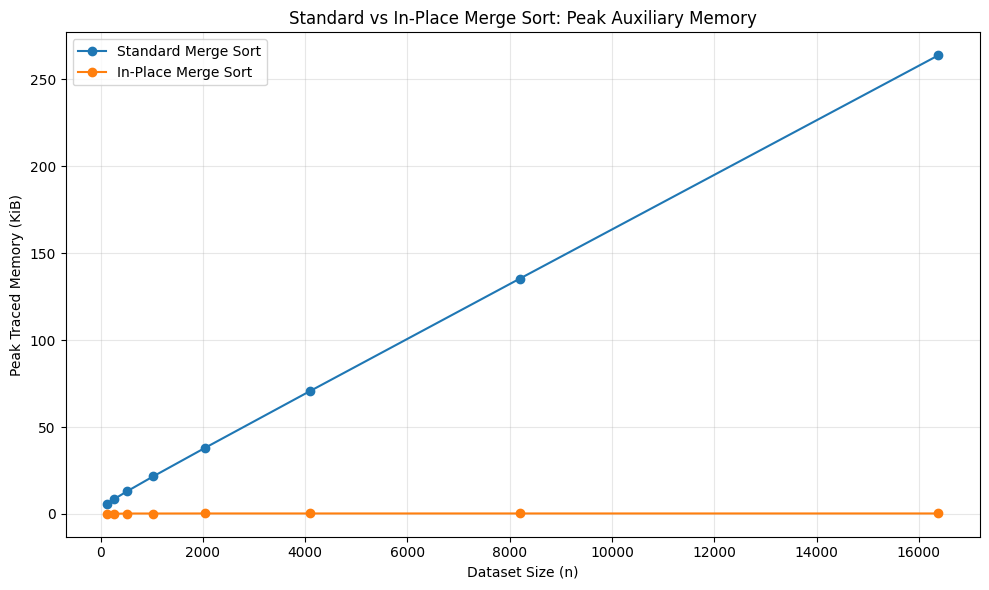

In [19]:
plt.figure(figsize=(10, 6))

plt.plot(
    memory_clean_summary["n"],
    memory_clean_summary["Standard Peak KiB"],
    marker="o",
    label="Standard Merge Sort"
)

plt.plot(
    memory_clean_summary["n"],
    memory_clean_summary["In-Place Peak KiB"],
    marker="o",
    label="In-Place Merge Sort"
)

plt.xlabel("Dataset Size (n)")
plt.ylabel("Peak Traced Memory (KiB)")

plt.title(
    "Standard vs In-Place Merge Sort: Peak Auxiliary Memory"
)

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

### **7.4 Memory-Growth Analysis**

Standard Merge Sort's measured peak memory increases steadily with $n$, while the in-place curve stays almost flat on the same scale. This supports the intended change from **$O(n)$ auxiliary space to $O(1)$ auxiliary space** for the implementations tested.

The memory saving is substantial, but Experiment 1 shows that it can be exchanged for much greater element movement.

## **8. Experiment 3: Runtime Analysis**

### **8.1 Method**

Runtime is measured with `time.perf_counter()` using the same clean implementations as the memory experiment. For each condition, both variants receive separate copies of the same input, copying occurs before timing, correctness is checked after timing, and each test is repeated five times. The **median runtime** is reported.

The same four arrangements and sizes (`64` to `2048`) from Experiment 1 are used so runtime can be compared directly with movement growth. Runtime is treated as empirical evidence, not as direct proof of Big-O complexity.

In [20]:
from time import perf_counter
from statistics import median


def measureRuntime(sort_function, original_data, repeats=5):
    """
    Measure median sorting runtime.

    The input copy is created before timing begins so that
    list-copying time is not included in the measurement.
    """

    runtimes = []
    expected = sorted(original_data)

    for _ in range(repeats):

        # Prepare input before timing
        test_data = original_data.copy()

        start_time = perf_counter()

        sort_function(test_data)

        end_time = perf_counter()

        # Correctness check occurs after timing
        if test_data != expected:
            raise ValueError(
                "Incorrect sorting result during runtime benchmark."
            )

        runtimes.append(
            end_time - start_time
        )

    return median(runtimes)

In [35]:
# Experiment 3: Runtime benchmark

runtime_sizes = [
    64,
    128,
    256,
    512,
    1024,
    2048
]

runtime_arrangements = [
    "Already Sorted",
    "Reverse Sorted",
    "Random",
    "Almost Sorted"
]

runtime_results = []

for arrangement in runtime_arrangements:

    print(f"Running arrangement: {arrangement}")

    for n in runtime_sizes:

        original_data = generateInPlaceTestData(
            n,
            arrangement
        )

        standard_runtime = measureRuntime(
            standardMergeSortClean,
            original_data,
            repeats=5
        )

        inplace_runtime = measureRuntime(
            inPlaceMergeSortClean,
            original_data,
            repeats=5
        )

        runtime_results.append({
            "Input Arrangement": arrangement,
            "n": n,
            "Standard Merge Sort Runtime (s)": standard_runtime,
            "In-Place Merge Sort Runtime (s)": inplace_runtime
        })

runtime_df = pd.DataFrame(runtime_results)

Running arrangement: Already Sorted
Running arrangement: Reverse Sorted
Running arrangement: Random
Running arrangement: Almost Sorted


In [36]:
runtime_summary = runtime_df.copy()

runtime_summary["Standard Runtime (ms)"] = (
    runtime_summary[
        "Standard Merge Sort Runtime (s)"
    ] * 1000
)

runtime_summary["In-Place Runtime (ms)"] = (
    runtime_summary[
        "In-Place Merge Sort Runtime (s)"
    ] * 1000
)

runtime_summary["In-Place / Standard Ratio"] = (
    runtime_summary["In-Place Runtime (ms)"]
    / runtime_summary["Standard Runtime (ms)"]
)

runtime_summary[
    [
        "Input Arrangement",
        "n",
        "Standard Runtime (ms)",
        "In-Place Runtime (ms)",
        "In-Place / Standard Ratio"
    ]
].round(4)

,Input Arrangement,n,Standard Runtime (ms),In-Place Runtime (ms),In-Place / Standard Ratio
0,Already Sorted,64,0.1170,0.0694,0.5932
1,Already Sorted,128,0.2619,0.1468,0.5605
2,Already Sorted,256,0.5669,0.3011,0.5311
3,Already Sorted,512,1.2359,0.7301,0.5907
4,Already Sorted,1024,2.7781,1.4885,0.5358
5,Already Sorted,2048,5.9738,3.0766,0.5150
6,Reverse Sorted,64,0.1205,0.2980,2.4730
7,Reverse Sorted,128,0.2652,1.0129,3.8194
8,Reverse Sorted,256,0.5859,3.4746,5.9304
9,Reverse Sorted,512,1.2828,15.6817,12.2246


In [37]:
runtime_2048_summary = (
    runtime_summary[
        runtime_summary["n"] == 2048
    ][
        [
            "Input Arrangement",
            "Standard Runtime (ms)",
            "In-Place Runtime (ms)",
            "In-Place / Standard Ratio"
        ]
    ]
    .reset_index(drop=True)
)

runtime_2048_summary.round(4)

,Input Arrangement,Standard Runtime (ms),In-Place Runtime (ms),In-Place / Standard Ratio
0,Already Sorted,5.9738,3.0766,0.5150
1,Reverse Sorted,7.8659,271.2540,34.4848
2,Random,8.1187,170.9018,21.0504
3,Almost Sorted,6.7669,3.7349,0.5519




### **8.2 Runtime Results at (n = 2048)**

| Input Arrangement  | Standard (ms) | In-Place (ms) | In-Place / Standard |
| ------------------ | ------------: | ------------: | ------------------: |
| **Already Sorted** |        5.9738 |        3.0766 |              0.5150 |
| **Almost Sorted**  |        6.7669 |        3.7349 |              0.5519 |
| **Random**         |        8.1187 |      170.9018 |             21.0504 |
| **Reverse Sorted** |        7.8659 |      271.2540 |             34.4848 |

With little shifting, the in-place variant was faster for **Already Sorted** and **Almost Sorted** data. However, for **Random** and **Reverse Sorted** inputs, repeated shifting dominated the runtime, making the in-place variant about **21.1×** and **34.5× slower**, respectively. This shows that the memory saving of the shift-based in-place implementation can come at a substantial runtime cost when the input requires many element shifts.


### **8.3 Runtime-Growth Visualisation**

The plots below show whether the runtime gap stays constant or widens as $n$ increases for each input arrangement.

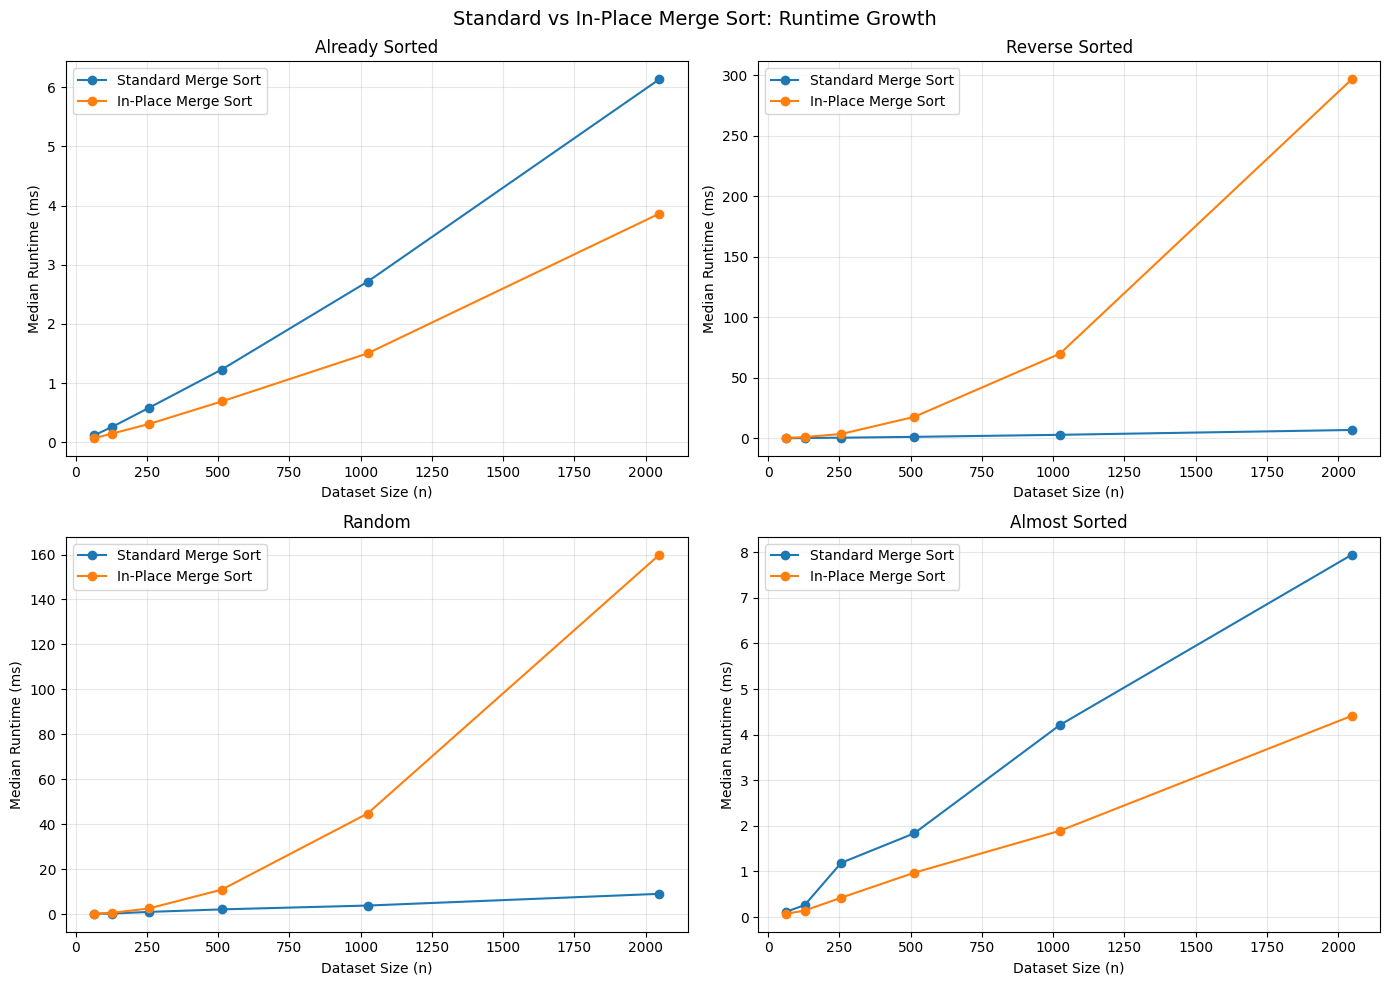

In [23]:
# Runtime growth across dataset sizes

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10)
)

axes = axes.flatten()

for ax, arrangement in zip(
    axes,
    runtime_arrangements
):
    subset = runtime_summary[
        runtime_summary["Input Arrangement"] == arrangement
    ]

    ax.plot(
        subset["n"],
        subset["Standard Runtime (ms)"],
        marker="o",
        label="Standard Merge Sort"
    )

    ax.plot(
        subset["n"],
        subset["In-Place Runtime (ms)"],
        marker="o",
        label="In-Place Merge Sort"
    )

    ax.set_title(arrangement)
    ax.set_xlabel("Dataset Size (n)")
    ax.set_ylabel("Median Runtime (ms)")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle(
    "Standard vs In-Place Merge Sort: Runtime Growth",
    fontsize=14
)

plt.tight_layout()
plt.show()

### **8.4 Analysis of Runtime Growth**

The runtime gap is strongly **input-dependent**.

* **Already Sorted / Almost Sorted:** the in-place variant remains faster across the tested sizes because very little shifting is required.
* **Random:** the performance gap increases as (n) grows. At (n=2048), the in-place variant is approximately **21.05× slower** than Standard Merge Sort.
* **Reverse Sorted:** repeated shifting produces the greatest cost. At (n=2048), the in-place variant is approximately **34.48× slower** than Standard Merge Sort.

At (n=2048), the movement ratios are **46.84×** for Random data and **93.55×** for Reverse Sorted data, while the corresponding runtime ratios are **21.05×** and **34.48×**. These ratios are not expected to match exactly because runtime also includes comparisons, loop operations, function calls, memory allocation, and Python interpreter overhead.

Overall, the runtime-growth results support the main trade-off of the shift-based in-place Merge Sort: **it saves auxiliary memory, but repeated element shifting can substantially increase execution time when the input is highly disordered.**

One thing though: if this graph was generated from a **different timing run** from your latest (n=2048) table, I would regenerate the graph using the same results before submission. Your table, graph, and written analysis should all show the same final experimental run.


## **9. Theoretical Complexity and Time-Space Trade-Off**

| Property | Standard Merge Sort | Shift-Based In-Place Variant |
| --- | --- | --- |
| **Best-case time** | $O(n\log n)$ | $O(n\log n)$ |
| **Worst-case time** | $O(n\log n)$ | $O(n^2)$ |
| **Auxiliary space** | $O(n)$ | $O(1)$ |
| **Temporary sublists** | Required | Not required |
| **Sensitivity to input order** | Limited | High |
| **Expected random-input time** | $O(n\log n)$ | $O(n^2)$ |

For a random permutation of distinct values, the expected number of inversions is proportional to $n^2$. Since this shift-based merge may need to shift values to correct these inversions, its expected runtime on random input can also approach $O(n^2)$. This is consistent with the rapid movement and runtime growth observed for the Random datasets.

Standard Merge Sort performs $O(n)$ merge work at each of $\log n$ levels, giving $O(n\log n)$ time, while its temporary sublists require $O(n)$ auxiliary space.

The shift-based variant removes those size-dependent lists. On Already Sorted data, no shifting is needed, but the merge levels still have to be processed, giving an $O(n\log n)$ best case. On highly disordered inputs, inserting values into earlier positions can require a quadratic number of shifts, so this **specific implementation** can reach $O(n^2)$ time.

Therefore, changing Merge Sort to be in-place is a genuine **time-space trade-off**: the algorithm uses much less auxiliary memory, but can take much longer when many values must be shifted.

## **10. Experimental Limitations**

* The case study uses **one simple shift-based in-place merge**; other in-place Merge Sort techniques may have different time, space, and implementation trade-offs.
* Runtime and exact `tracemalloc` measurements depend on the Python environment, so the **overall growth trends** are more meaningful than individual values.
* The four controlled input arrangements do not represent every possible input distribution.
* The main movement and runtime experiments use powers of two from **64 to 2048**, although correctness testing also includes odd-sized inputs.
* The movement metric measures the **in-array shifts introduced by the tested in-place merge**; it does not measure the allocation or copying associated with Standard Merge Sort's temporary merge storage.

The experiment therefore demonstrates the trade-off between the **two implementations tested**, rather than proving that one approach is universally better.

## **11. Conclusion**

This case study demonstrates how a traditionally out-of-place Merge Sort implementation can be modified to operate in-place, and the performance cost introduced by that change.

The experiments show that:

* Standard Merge Sort's auxiliary memory grows with (n), while the tested bottom-up in-place version remains approximately constant.
* For the tested power-of-two datasets, both implementations make identical comparison counts, indicating that their main difference is not the number of ordering decisions.
* The in-place variant requires very little shifting for **Already Sorted** and **Almost Sorted** data, but repeated shifting causes movement and runtime to increase substantially for **Random** and **Reverse Sorted** inputs.
* At (n=2048), the in-place variant is approximately **21.05× slower** than Standard Merge Sort for Random data and **34.48× slower** for Reverse Sorted data.

The theoretical trade-off for the tested implementations is:
$$\text{Standard Merge Sort: } O(n\log n)\text{ time},\ O(n)\text{ auxiliary space}$$

$$\text{Shift-based In-Place Variant: } O(n\log n)\text{ best-case},\ O(n^2)\text{ worst-case},\ O(1)\text{ auxiliary space}$$

**Key Finding**

* In-place sorting describes a **memory property**, not a guarantee of better overall performance.
* The tested shift-based variant is most beneficial when **auxiliary memory is limited and little shifting is required**.
* Standard Merge Sort is preferable when **predictable (O(n log n)) runtime** is more important than reducing auxiliary memory.

One more thing: I like **“Key Finding” better than “Final finding”** here. It looks more report-like and matches the style you were using earlier.


## References

1. Pasanen, T. (1999). *In-place algorithms for sorting problems*. ACM SIGACT News, 30(2), 61.  
   https://doi.org/10.1145/568547.568565

2. Huang, B. C., & Langston, M. A. (1992). *Fast stable merging and sorting in constant extra space*. The Computer Journal, 35(6), 643–650.  
   https://doi.org/10.1093/comjnl/35.6.643

3. Chen, J. C. (2006). *A simple algorithm for in-place merging*. Information Processing Letters, 98(1), 34–40.  
   https://doi.org/10.1016/j.ipl.2005.11.018

# Individual Investigation: Sorting Stability

### **Name:** TOH KE TING  
### **Individual Topic:** Stability

This investigation evaluates sorting stability, examines how stability depends on implementation details, and studies the practical cost of modifying an unstable Selection Sort into a stable version.

The investigation focuses on three questions:

1. What does it mean for a sorting algorithm to be stable?
2. How can an unstable sorting algorithm be modified to preserve stability?
3. What practical cost is introduced when stability is preserved?

## 1. Definition and Evaluation

A sorting algorithm is **stable** when records with equal sorting keys retain their original relative order after sorting.

Stability is meaningful only when equal-key records are distinguishable. For example, consider:

$$
(A, 2),\ (B, 2),\ (C, 1)
$$

If the second field is the sorting key, both $A$ and $B$ have key 2. Since $A$ appears before $B$ in the original input, a stable sorting algorithm must still keep $A$ before $B$ after sorting.

Therefore, stability concerns more than whether the keys are in the correct numerical order. A result can be correctly sorted by key but still be unstable if equal-key records have changed their relative order.

Stability is also **implementation-dependent**. Small changes in comparison or movement rules can change whether a particular implementation is stable.

| CA2 Implementation | Stable? | Reason |
|---|---|---|
| Bubble Sort | Yes | Swaps only when the left key is strictly greater (`>`), so equal-key records are not exchanged. |
| Merge Sort | Yes | When keys are equal, `<=` selects the left-half record first, preserving its earlier position. |
| Three-Way Quick Sort | No | Non-adjacent partition swaps may move equal-key records past one another. |
| Heap Sort | No | Heap construction and root extraction use distant swaps without preserving equal-key order. |

For example, changing the Bubble Sort condition from `>` to `>=` could make that implementation unstable because equal-key records would then be allowed to swap. Similarly, Merge Sort remains stable here because ties are resolved by selecting the record from the left half first.

## 2. Case Study: Standard vs Stable Selection Sort

To investigate how an unstable sorting algorithm can be modified, I use **Selection Sort** as a case study.

### 2.1 Standard Selection Sort

Standard Selection Sort repeatedly finds the minimum record from the unsorted portion of the list and swaps it directly with the record at the current position.

The implementation below also records several operation counts:

- **Comparisons** — comparisons between sorting keys.
- **Swaps** — direct exchanges between two records.
- **Shifts** — record movements used by the stable version.
- **Record Writes** — the number of records written into list positions.

A direct swap is counted as **two record writes** because two list positions are overwritten.

Standard Selection Sort is generally **unstable** because a long-distance swap can move one equal-key record past another.

In [24]:
def selectionSortUnstable(records, key=lambda record: record[1]):
    comparisons = 0
    swaps = 0
    record_writes = 0

    for i in range(len(records) - 1):
        min_index = i

        for j in range(i + 1, len(records)):
            comparisons += 1

            if key(records[j]) < key(records[min_index]):
                min_index = j

        if min_index != i:
            records[i], records[min_index] = (
                records[min_index],
                records[i]
            )

            swaps += 1
            record_writes += 2

    return {
        "Comparisons": comparisons,
        "Swaps": swaps,
        "Shifts": 0,
        "Record Writes": record_writes
    }

### 2.2 Making Selection Sort Stable

The unstable Selection Sort can be modified by replacing the direct minimum swap with **shifting and insertion**.

Instead of swapping the minimum record directly with the first unsorted record:

1. **Store the minimum record temporarily.**
2. **Shift every record between the current position and the minimum position one place to the right.**
3. **Insert the minimum record into the current position.**

Because the intervening records move together without crossing one another, their relative order is preserved.

This stable version still operates directly on the original list and uses only a constant number of temporary variables, so its auxiliary space remains:

$$
O(1)
$$

However, preserving stability may require many more record movements than the direct-swap version.

In [25]:
def selectionSortStable(records, key=lambda record: record[1]):
    comparisons = 0
    shifts = 0
    record_writes = 0

    for i in range(len(records) - 1):
        min_index = i

        for j in range(i + 1, len(records)):
            comparisons += 1

            if key(records[j]) < key(records[min_index]):
                min_index = j

        if min_index != i:
            minimum_record = records[min_index]

            # Shift records one position to the right
            while min_index > i:
                records[min_index] = records[min_index - 1]

                shifts += 1
                record_writes += 1
                min_index -= 1

            # Insert the minimum record
            records[i] = minimum_record
            record_writes += 1

    return {
        "Comparisons": comparisons,
        "Swaps": 0,
        "Shifts": shifts,
        "Record Writes": record_writes
    }

### 2.3 Checking Stability

Correct sorting alone is not sufficient to prove stability.

The helper function below checks whether records with the same sorting key remain in the same relative order before and after sorting.

This requires **distinguishable records**. Repeated standalone values such as:

\[
[2,2,1]
\]

cannot demonstrate stability because the two values `2` are indistinguishable.

Using labelled records such as `(A, 2)` and `(B, 2)` makes it possible to observe whether their relative order changes.

In [26]:
from collections import defaultdict


def relativeOrderByKey(records, key=lambda record: record[1]):
    order = defaultdict(list)

    for record in records:
        order[key(record)].append(record[0])

    return dict(order)


def isStable(original_records, sorted_records,
             key=lambda record: record[1]):

    original_order = relativeOrderByKey(
        original_records,
        key
    )

    sorted_order = relativeOrderByKey(
        sorted_records,
        key
    )

    for sorting_key in original_order:
        if sorted_order[sorting_key] != original_order[sorting_key]:
            return False

    return True

### 2.4 Stability Case Study: Equal-Score Student Records

Consider the following records sorted by the second field:

\[
(A,2),\ (B,2),\ (C,1)
\]

Originally, \(A\) appears before \(B\), and both have the same sorting key.

#### Standard Selection Sort

The minimum record is `(C, 1)`. Standard Selection Sort swaps it directly with `(A, 2)`:

$$
(A,2),\ (B,2),\ (C,1)
$$

becomes:

$$
(C,1),\ (B,2),\ (A,2)
$$

The keys are correctly sorted as \(1,2,2\), but the equal-key order changes from:

$$
A \rightarrow B
$$

to:

$$
B \rightarrow A
$$

Therefore, the standard implementation is **unstable**.

#### Stable Shifting Version

The stable version removes `(C, 1)`, shifts `(A, 2)` and `(B, 2)` one position to the right, and inserts `(C, 1)` at the front:

$$
(C,1),\ (A,2),\ (B,2)
$$

The original order:

$$
A \rightarrow B
$$

is preserved.

Therefore, the modified implementation is **stable**.

In [27]:
case_study_records = [
    ("A", 2),
    ("B", 2),
    ("C", 1)
]

case_unstable_result = case_study_records.copy()
case_stable_result = case_study_records.copy()

case_unstable_metrics = selectionSortUnstable(
    case_unstable_result
)

case_stable_metrics = selectionSortStable(
    case_stable_result
)

print("Original:")
print(case_study_records)

print("\nStandard Selection Sort:")
print(case_unstable_result)
print(
    "Stable:",
    isStable(
        case_study_records,
        case_unstable_result
    )
)
print("Metrics:", case_unstable_metrics)

print("\nStable Selection Sort:")
print(case_stable_result)
print(
    "Stable:",
    isStable(
        case_study_records,
        case_stable_result
    )
)
print("Metrics:", case_stable_metrics)

Original:
[('A', 2), ('B', 2), ('C', 1)]

Standard Selection Sort:
[('C', 1), ('B', 2), ('A', 2)]
Stable: False
Metrics: {'Comparisons': 3, 'Swaps': 1, 'Shifts': 0, 'Record Writes': 2}

Stable Selection Sort:
[('C', 1), ('A', 2), ('B', 2)]
Stable: True
Metrics: {'Comparisons': 3, 'Swaps': 0, 'Shifts': 2, 'Record Writes': 3}


### Case Study Result

Both implementations produced the correct ascending key order, but only the shifting version preserved the relative order of the equal-key records.

For this small case:

- Standard Selection Sort performed **3 comparisons**, **1 swap**, and **2 record writes**.
- Stable Selection Sort performed **3 comparisons**, **2 shifts**, and **3 record writes**.

The number of key comparisons did not change because both implementations use the same process to locate the minimum record.

The difference comes from **how the minimum record is moved**. Standard Selection Sort performs one direct swap, while the stable version shifts the intervening records before inserting the minimum.

This shows that stability can be changed by the movement rule without changing the fundamental comparison structure of Selection Sort.

## 3. Complexity Cost of Preserving Stability

For a dataset of size \(n\), both Selection Sort implementations search the remaining unsorted section for the minimum during every pass.

Therefore, both perform exactly:

$$
\frac{n(n-1)}{2}
$$

key comparisons.

This gives:

$$
\Theta(n^2)
$$

time complexity for both implementations.

Their auxiliary-space requirement is also:

$$
O(1)
$$

because both operate directly on the original list and use only a constant number of temporary variables.

The main difference is **record movement**.

### Standard Selection Sort

Standard Selection Sort performs at most:

$$
n-1
$$

swaps.

Since each swap writes two records, this gives at most:

$$
2(n-1)
$$

record writes, which is:

$$
O(n)
$$

### Stable Shifting Version

The stable version may need to shift many records during each pass.

In a high-movement case, the number of shifts can grow as:

$$
\Theta(n^2)
$$

Therefore, the stable implementation can require:

$$
\Theta(n^2)
$$

record writes even though its overall sorting time remains \(\Theta(n^2)\).

The following experiments investigate this movement cost.

## 4. Experiment 1 — Growth of Record-Movement Cost

### Objective

The first experiment investigates how the cost of the stable modification grows as the dataset size increases.

Reverse-ordered records with unique sorting keys are used because they create a **high-movement case** for the shifting implementation.

The tested dataset sizes are:

$$
n = 10,\ 50,\ 100,\ 500
$$

For every dataset size:

1. The Standard and Stable Selection Sort implementations receive separate copies of the same input.
2. Both outputs are checked against Python's `sorted()` result.
3. The number of key comparisons and record writes is recorded.

The records in this experiment use unique sorting keys. Therefore, this experiment is **not intended to demonstrate stability itself**. Stability has already been demonstrated using distinguishable equal-key records in the earlier case study.

Instead, this experiment measures the **cost of the modification used to preserve stability**.

In [28]:
movement_results = []

for n in [10, 50, 100, 500]:
    original_records = [
        (f"R{value}", value)
        for value in range(n, 0, -1)
    ]

    unstable_data = original_records.copy()
    stable_data = original_records.copy()

    unstable_metrics = selectionSortUnstable(
        unstable_data
    )

    stable_metrics = selectionSortStable(
        stable_data
    )

    expected = sorted(
        original_records,
        key=lambda record: record[1]
    )

    assert unstable_data == expected
    assert stable_data == expected

    movement_results.append({
        "Dataset Size (n)": n,
        "Standard Comparisons":
            unstable_metrics["Comparisons"],
        "Stable Comparisons":
            stable_metrics["Comparisons"],
        "Standard Record Writes":
            unstable_metrics["Record Writes"],
        "Stable Record Writes":
            stable_metrics["Record Writes"]
    })

stability_cost_df = pd.DataFrame(movement_results)
stability_cost_df

,Dataset Size (n),Standard Comparisons,Stable Comparisons,Standard Record Writes,Stable Record Writes
0,10,45,45,10,54
1,50,1225,1225,50,1274
2,100,4950,4950,100,5049
3,500,124750,124750,500,125249


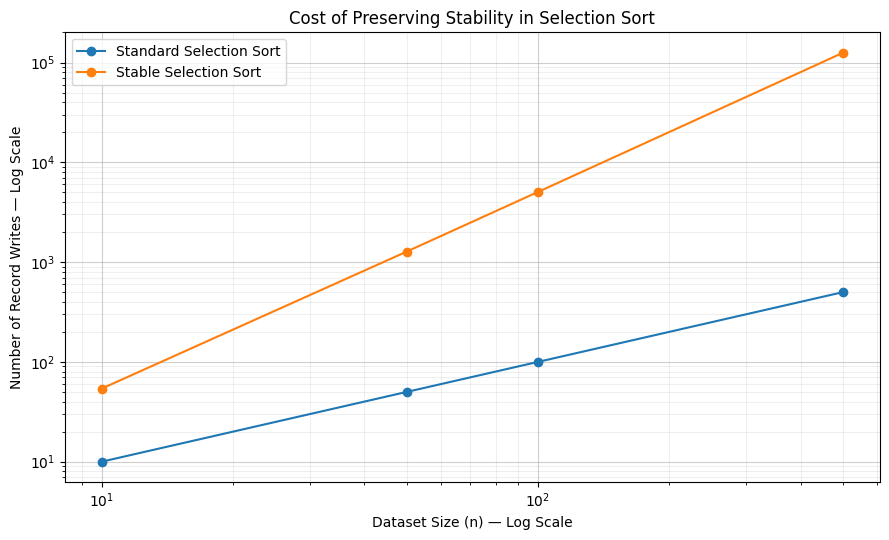

In [29]:
plt.figure(figsize=(9, 5.5))

plt.plot(
    stability_cost_df["Dataset Size (n)"],
    stability_cost_df["Standard Record Writes"],
    marker="o",
    label="Standard Selection Sort"
)

plt.plot(
    stability_cost_df["Dataset Size (n)"],
    stability_cost_df["Stable Record Writes"],
    marker="o",
    label="Stable Selection Sort"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Dataset Size (n) — Log Scale")
plt.ylabel("Number of Record Writes — Log Scale")
plt.title(
    "Cost of Preserving Stability in Selection Sort"
)

plt.legend()
plt.grid(True, which="major", alpha=0.6)
plt.grid(True, which="minor", alpha=0.2)

plt.tight_layout()
plt.show()

### 4.1 Analysis of Dataset-Size Growth

Both Selection Sort implementations performed the same number of key comparisons for every dataset size.

This is expected because both implementations use exactly the same procedure to find the minimum record.

The comparison count follows:

$$
\frac{n(n-1)}{2}
$$

which is consistent with the theoretical:

$$
\Theta(n^2)
$$

time complexity of Selection Sort.

However, their record-movement behaviour was very different.

For the reverse-ordered datasets, Standard Selection Sort required only a limited number of direct swaps. In contrast, the stable version repeatedly shifted large sections of the list in order to insert each minimum record without disturbing the relative order of the intervening records.

At \(n=500\):

- Both implementations performed **124,750 key comparisons**.
- Standard Selection Sort required **500 record writes**.
- Stable Selection Sort required **125,249 record writes**.

The ratio is:

$$
\frac{125249}{500} \approx 250.5
$$

Therefore, in this reverse-ordered high-movement case, preserving stability through shifting required approximately **250.5 times more record writes**.

This demonstrates that two implementations can have the same $$\Theta(n^2)$$ time complexity and $$O(1)$$ auxiliary-space classification while having very different practical data-movement costs.

## 5. Experiment 2 — Effect of Input Arrangement

### Objective

Experiment 1 used reverse-ordered data to expose a high-movement case. However, the 250.5× increase should not be assumed to occur for every input.

The second experiment therefore investigates whether the cost of the stable shifting modification depends on the **initial arrangement of the records**.

The dataset size is fixed at:

$$
n=500
$$

so that only the input arrangement changes.

Four arrangements are tested:

1. **Already Sorted** — records are already in ascending key order.
2. **Almost Sorted** — only a small local disorder is introduced.
3. **Random** — unique keys are shuffled using a fixed random seed.
4. **Reverse Sorted** — records appear in descending key order.

For each arrangement, both implementations receive separate copies of the same records.

The experiment measures:

- key comparisons,
- record writes,
- and stable-version shifts.

As in Experiment 1, these datasets use unique sorting keys to isolate the cost of record movement. The stability property itself is demonstrated separately using equal-key labelled records.

In [30]:
import random
import pandas as pd

n = 500
random.seed(1507)

# Create four different input arrangements
stability_input_cases = {
    "Already Sorted": [
        (f"R{i}", i)
        for i in range(n)
    ],

    "Almost Sorted": [
        (f"R{i}", i)
        for i in range(n)
    ],

    "Random": None,

    "Reverse Sorted": [
        (f"R{i}", n - i)
        for i in range(n)
    ]
}

# Make the almost-sorted input slightly disordered
stability_input_cases["Almost Sorted"][-1], \
stability_input_cases["Almost Sorted"][-2] = (
    stability_input_cases["Almost Sorted"][-2],
    stability_input_cases["Almost Sorted"][-1]
)

# Create a reproducible random input
random_keys = list(range(n))
random.shuffle(random_keys)

stability_input_cases["Random"] = [
    (f"R{i}", key)
    for i, key in enumerate(random_keys)
]


arrangement_results = []

for case_name, original_records in stability_input_cases.items():

    # Separate copies because both sorting functions modify the list
    standard_data = original_records.copy()
    stable_data = original_records.copy()

    # Functions return metrics only
    standard_metrics = selectionSortUnstable(
        standard_data
    )

    stable_metrics = selectionSortStable(
        stable_data
    )

    # Correct sorted result
    expected = sorted(
        original_records,
        key=lambda record: record[1]
    )

    # Verify sorting correctness
    assert standard_data == expected
    assert stable_data == expected

    arrangement_results.append({
        "Input Arrangement": case_name,

        "Standard Comparisons":
            standard_metrics["Comparisons"],

        "Stable Comparisons":
            stable_metrics["Comparisons"],

        "Standard Record Writes":
            standard_metrics["Record Writes"],

        "Stable Record Writes":
            stable_metrics["Record Writes"],

        "Stable Shifts":
            stable_metrics["Shifts"]
    })


stability_arrangement_df = pd.DataFrame(
    arrangement_results
)

stability_arrangement_df

,Input Arrangement,Standard Comparisons,Stable Comparisons,Standard Record Writes,Stable Record Writes,Stable Shifts
0,Already Sorted,124750,124750,0,0,0
1,Almost Sorted,124750,124750,2,2,1
2,Random,124750,124750,988,63244,62750
3,Reverse Sorted,124750,124750,500,125249,124750


### Visualisation Note

The record-write counts range from 0 to more than 125,000.

A normal linear y-axis would make the smaller values for Already Sorted, Almost Sorted, and Standard Selection Sort difficult to see.

Therefore, a **symmetric-logarithmic (`symlog`) scale** is used so that zero and small values remain visible while still showing the much larger record-write counts for Random and Reverse Sorted inputs.

The graph highlights that the largest difference between the two implementations occurs when records must move across long distances.

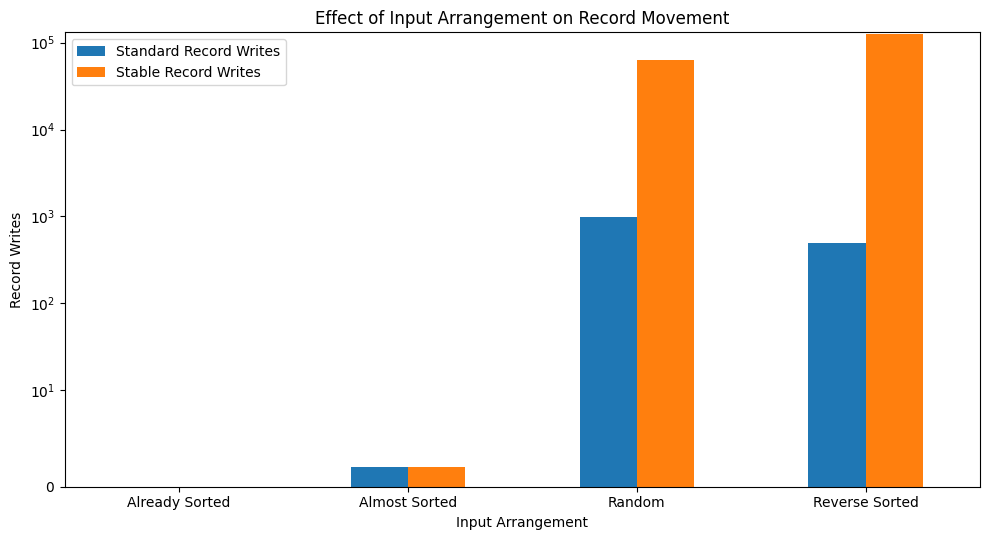

In [31]:
plot_df = stability_arrangement_df.set_index(
    "Input Arrangement"
)

ax = plot_df[
    [
        "Standard Record Writes",
        "Stable Record Writes"
    ]
].plot(
    kind="bar",
    figsize=(10, 5.5)
)

ax.set_yscale("symlog", linthresh=10)

plt.ylabel("Record Writes")
plt.xlabel("Input Arrangement")
plt.title(
    "Effect of Input Arrangement on Record Movement"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 5.1 Analysis of Input Arrangement

For all four input arrangements at \(n=500\), both Selection Sort implementations performed exactly:

$$
124,750
$$

key comparisons.

This is expected because Selection Sort scans the remaining unsorted section to locate the minimum on every pass regardless of the original arrangement.

However, the amount of record movement changed substantially.

| Input Arrangement | Standard Record Writes | Stable Record Writes | Stable Shifts |
|---|---:|---:|---:|
| Already Sorted | 0 | 0 | 0 |
| Almost Sorted | 2 | 2 | 1 |
| Random | 988 | 63,244 | 62,750 |
| Reverse Sorted | 500 | 125,249 | 124,750 |

#### Already Sorted

Neither implementation required any record writes.

The minimum record was already at the beginning of every unsorted section, so no swap or shift was necessary.

This shows that the stable shifting version is **not always expensive**.

#### Almost Sorted

Only a small local disorder was introduced.

Both implementations required only **2 record writes**, while the stable version performed only **1 shift**.

Therefore, when the minimum record is already close to its correct position, preserving stability introduces very little movement.

#### Random

For the Random input:

- Standard Selection Sort used **988 record writes**.
- Stable Selection Sort used **63,244 record writes**.
- The stable implementation performed **62,750 shifts**.

The stable version therefore required approximately:

$$
\frac{63244}{988} \approx 64.0
$$

times more record writes.

Randomly positioned minimum records frequently had to move across several existing records, so the shifting cost increased substantially.

#### Reverse Sorted

The Reverse Sorted input produced the largest movement cost:

- Standard Selection Sort used **500 record writes**.
- Stable Selection Sort used **125,249 record writes**.
- The stable version performed **124,750 shifts**.

This is approximately:

$$
\frac{125249}{500} \approx 250.5
$$

times more record writes.

### Main Finding

The experiment shows that preserving stability through shifting does **not** change Selection Sort's number of key comparisons, but its record-movement cost is strongly **input-dependent**.

The 250.5× increase observed for Reverse Sorted data should therefore be interpreted as a **high-movement case**, not as the expected cost for every input arrangement.

## 6. Alternative Approach: Original-Index Decoration

An alternative approach, **not experimentally evaluated in this
investigation**, is to attach each record's original position and compare:

`(key, original_index)`

When two records have the same sorting key, the original index acts as a
tie-breaker, so the record that appeared earlier in the input remains first.

This approach preserves the underlying sorting algorithm's asymptotic time
complexity, but storing an original index for each of the `n` records
requires $O(n)$ additional metadata.

Therefore, the two approaches illustrate different trade-offs:

| Approach | Preserves Tie Order? | Auxiliary Cost | Main Trade-off |
|---|---|---|---|
| Stable shifting | Yes | $O(1)$ | Up to $\Theta(n^2)$ record movement |
| Original-index decoration | Yes | $O(n)$ metadata | Additional memory |

The original-index method is included as a researched alternative rather
than an experimentally benchmarked method in this investigation.

## 7. Real Uses of Stable Sorting

### 7.1 Multi-Key Sorting

Stable sorting is useful when records must be sorted by multiple fields.

Python's sorting operations are stable. Therefore, records can first be sorted by a secondary field and then stably sorted by a primary field without losing the earlier secondary order.

For example, student records can first be sorted by **name** and then stably sorted by **class**.

Within each class, the students remain in name order.

This is useful because the ordering established by the first sorting stage is preserved among records that have equal values in the second sorting stage.

### 7.2 Text-Processing Pipelines

GNU `sort --stable` preserves the original relative order of lines whose selected sorting keys compare equally.

For example, suppose log records have already been arranged chronologically by timestamp.

If they are then stably sorted by severity, records with the same severity retain their earlier chronological order.

This prevents meaningful ordering established by an earlier processing stage from being lost.

## 8. Experimental Limitations

Several limitations should be considered when interpreting the results.

1. **Record writes are logical operation counts rather than actual bytes copied.**  
   Every record write is treated as having the same cost. In a real application, moving a record containing many fields may be more expensive than moving a small record.

2. **The movement experiments use unique sorting keys.**  
   These experiments are designed to isolate the cost of the stable shifting modification. Stability itself is demonstrated separately using distinguishable records with equal keys.

3. **The Random arrangement uses one fixed random seed.**  
   The result is reproducible, but the exact value of 63,244 stable record writes should not be interpreted as the average for every possible random arrangement.

4. **Runtime was not used as the primary measure.**  
   Execution time can be affected by hardware, operating-system activity, and Python overhead. Record-write counts provide a more implementation-focused measure of the additional movement caused by the stable modification.

5. **The original-index decoration approach was not experimentally benchmarked.**  
   It is included as a researched alternative to demonstrate a different stability trade-off involving additional memory.

## 9. Conclusion

This investigation shows that stability concerns more than obtaining the correct sorted key order. When records with equal keys contain meaningful secondary information, their original relative order may also need to be preserved.

The Selection Sort case study demonstrated that standard direct swapping can reverse equal-key records, while replacing the swap with shifting and insertion preserves their original order.

Both implementations still perform:

$$
\frac{n(n-1)}{2}
$$

key comparisons and therefore remain:

$$
\Theta(n^2)
$$

in time complexity with:

$$
O(1)
$$

auxiliary space.

However, the experiments revealed an important practical difference in record movement.

The dataset-size experiment showed that the stable shifting version can require \(\Theta(n^2)\) record movement in a high-movement case. At \(n=500\), the Reverse Sorted input required 125,249 stable record writes compared with only 500 for Standard Selection Sort, approximately **250.5× more**.

The input-arrangement experiment showed that this cost is not fixed. At the same \(n=500\):

- Already Sorted required **0** stable record writes.
- Almost Sorted required **2**.
- Random required **63,244**.
- Reverse Sorted required **125,249**.

Therefore, the practical cost of preserving stability through shifting depends strongly on the arrangement of the input even though the asymptotic time and auxiliary-space classifications remain unchanged.

An alternative original-index approach can preserve tie order using $O(n)$ additional metadata, demonstrating a different trade-off between memory usage and record movement.

Overall, algorithm selection should consider not only Big-O time complexity, but also **stability requirements, auxiliary space, input characteristics, and data-movement cost**.

## References

[1] NIST Dictionary of Algorithms and Data Structures, **“stable.”**  
https://xlinux.nist.gov/dads/HTML/stable.html

[2] Python Software Foundation, **“Sorting Techniques — Sort Stability and Complex Sorts.”**  
https://docs.python.org/3/howto/sorting.html

[3] GNU Coreutils Manual, **“sort: Sort Text Files.”**  
https://www.gnu.org/software/coreutils/manual/coreutils.html